In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

In [3]:
df = pd.read_csv('./raw_data/airlines_flights_data.csv',index_col='index')

df.shape

(300153, 11)

In [4]:
from sklearn.model_selection import GroupShuffleSplit

# pilih data training only sebelum melakukan EDA untuk menghindari data leakage
df_all = df.copy()
duplicate_count = int(df_all.duplicated().sum())
df_all = df_all.drop_duplicates().copy()
feature_cols = [c for c in df_all.columns if c not in ['price', 'flight']]


# input identik (walaupun harga/flight berbeda) harus tetap pada satu partisi.
feature_groups = pd.util.hash_pandas_object(df_all[feature_cols], index=False)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
dev_pos, test_pos = next(splitter.split(df_all, groups=feature_groups))
dev = df_all.iloc[dev_pos]
splitter_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=43)
train_pos, val_pos = next(splitter_val.split(dev, groups=feature_groups.loc[dev.index]))
train_raw, val_raw, test_raw = dev.iloc[train_pos].copy(), dev.iloc[val_pos].copy(), df_all.iloc[test_pos].copy()


for a,b in [(train_raw,val_raw),(train_raw,test_raw),(val_raw,test_raw)]:
    assert set(feature_groups.loc[a.index]).isdisjoint(feature_groups.loc[b.index])


df = train_raw.copy()
print('Total:', len(df_all), '| Duplicates removed:', duplicate_count)
print('Train / Validation / Test:', len(train_raw), len(val_raw), len(test_raw))
print(pd.DataFrame({k:v['class'].value_counts(normalize=True) for k,v in
                    [('train',train_raw),('validation',val_raw),('test',test_raw)]}))

Total: 300153 | Duplicates removed: 0
Train / Validation / Test: 180090 60050 60013
             train  validation    test
class                                 
Economy   0.687734    0.689176  0.6903
Business  0.312266    0.310824  0.3097


In [5]:
df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
index,,,,,,,,,,,
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
5,Vistara,UK-945,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.33,1,5955
7,Vistara,UK-951,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.17,1,6060


In [6]:
df.tail()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
index,,,,,,,,,,,
300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [7]:
for dtypes,cols in df.dtypes.groupby(df.dtypes.astype(str)).groups.items():
    print(f'{dtypes} : {cols} \n')


float64 : Index(['duration'], dtype='str') 

int64 : Index(['days_left', 'price'], dtype='str') 

str : Index(['airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class'],
      dtype='str') 



In [8]:
df.describe()

,duration,days_left,price
count,180090.000000,180090.000000,180090.000000
mean,12.233018,25.994875,20947.712560
std,7.182593,13.556511,22742.625348
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4784.000000
50%,11.250000,26.000000,7426.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,117307.000000


In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 180090 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           180090 non-null  str    
 1   flight            180090 non-null  str    
 2   source_city       180090 non-null  str    
 3   departure_time    180090 non-null  str    
 4   stops             180090 non-null  str    
 5   arrival_time      180090 non-null  str    
 6   destination_city  180090 non-null  str    
 7   class             180090 non-null  str    
 8   duration          180090 non-null  float64
 9   days_left         180090 non-null  int64  
 10  price             180090 non-null  int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 16.5 MB


**These are the main Features/Columns available in the dataset :**
1) Airline: The name of the airline company is stored in the airline column. It is a categorical feature having 6 different airlines.

2) Flight: Flight stores information regarding the plane's flight code. It is a categorical feature.

3) Source City: City from which the flight takes off. It is a categorical feature having 6 unique cities.

4) Departure Time: This is a derived categorical feature obtained created by grouping time periods into bins. It stores information about the departure time and have 6 unique time labels.

5) Stops: A categorical feature with 3 distinct values that stores the number of stops between the source and destination cities.

6) Arrival Time: This is a derived categorical feature created by grouping time intervals into bins. It has six distinct time labels and keeps information about the arrival time.

7) Destination City: City where the flight will land. It is a categorical feature having 6 unique cities.

8) Class: A categorical feature that contains information on seat class; it has two distinct values: Business and Economy.

9) Duration: A continuous feature that displays the overall amount of time it takes to travel between cities in hours.

10) Days Left: This is a derived characteristic that is calculated by subtracting the trip date by the booking date.

11) Price: Target variable stores information of the ticket price.

In [10]:
print(f'Duplicated Row Dataset  : {df.duplicated().sum()} \n')
print(f'Null Column Dataset : \n{df.isna().sum()}')

Duplicated Row Dataset  : 0 

Null Column Dataset : 
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64


In [11]:

for i in ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']:
  print(f'Value Count {i} : {df[i].value_counts().count()}\n')

Value Count airline : 6

Value Count flight : 1544

Value Count source_city : 6

Value Count departure_time : 6

Value Count stops : 3

Value Count arrival_time : 6

Value Count destination_city : 6

Value Count class : 2



In [12]:
for i in ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']:
       print(f"cols {i} : {df[i].unique()}\n")

cols airline : <StringArray>
['SpiceJet', 'Vistara', 'GO_FIRST', 'Indigo', 'Air_India', 'AirAsia']
Length: 6, dtype: str

cols flight : <StringArray>
['SG-8709',  'UK-995',  'UK-963',  'UK-945',  'UK-951',  'G8-336',  'G8-392',
 '6E-6202',  '6E-549',  'AI-887',
 ...
 '6E-7183', 'SG-6017', '6E-7208', '6E-7252',  '6E-557', '6E-7141', '6E-7259',
 '6E-7127',  'AI-433',  'AI-652']
Length: 1544, dtype: str

cols source_city : <StringArray>
['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
Length: 6, dtype: str

cols departure_time : <StringArray>
['Evening', 'Morning', 'Afternoon', 'Early_Morning', 'Night', 'Late_Night']
Length: 6, dtype: str

cols stops : <StringArray>
['zero', 'one', 'two_or_more']
Length: 3, dtype: str

cols arrival_time : <StringArray>
['Night', 'Afternoon', 'Morning', 'Evening', 'Early_Morning', 'Late_Night']
Length: 6, dtype: str

cols destination_city : <StringArray>
['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi']
Length: 6, dtype

# **Exploratory Data Analysis**

Distribusi dan Hubungan Fitur

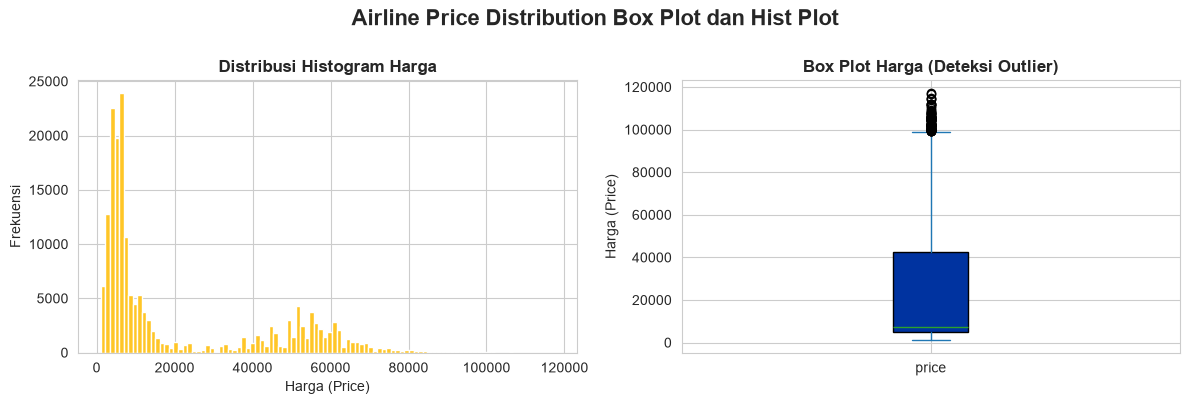

In [13]:
fig,ax = plt.subplots(1,2,figsize=(12, 4))
df['price'].plot(kind='hist',ax=ax[0], bins=100, color=['#FFC627'])
ax[0].set_title('Distribusi Histogram Harga', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Harga (Price)')
ax[0].set_ylabel('Frekuensi')

df['price'].plot(kind='box',ax=ax[1],patch_artist=True, boxprops=dict(facecolor='#0033A0', color='black') )
# boxprops = dict(linestyle='-', linewidth=2, color='')

ax[1].set_title('Box Plot Harga (Deteksi Outlier)', fontsize=12, fontweight='bold')
ax[1].set_ylabel('Harga (Price)')
fig.suptitle('Airline Price Distribution Box Plot dan Hist Plot',
             y=1.00, fontsize=16, fontweight='bold', ha='center')
plt.tight_layout()
plt.show()

**Interpretasi:** Harga tiket pesawat memiliki distribusi yang tidak merata dan menunjukkan adanya beberapa segmen harga. Kondisi ini mengindikasikan pentingnya mempertimbangkan karakteristik penerbangan dalam membangun model prediksi harga.


/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_64918/3847370213.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_cat = df.select_dtypes(include='object')


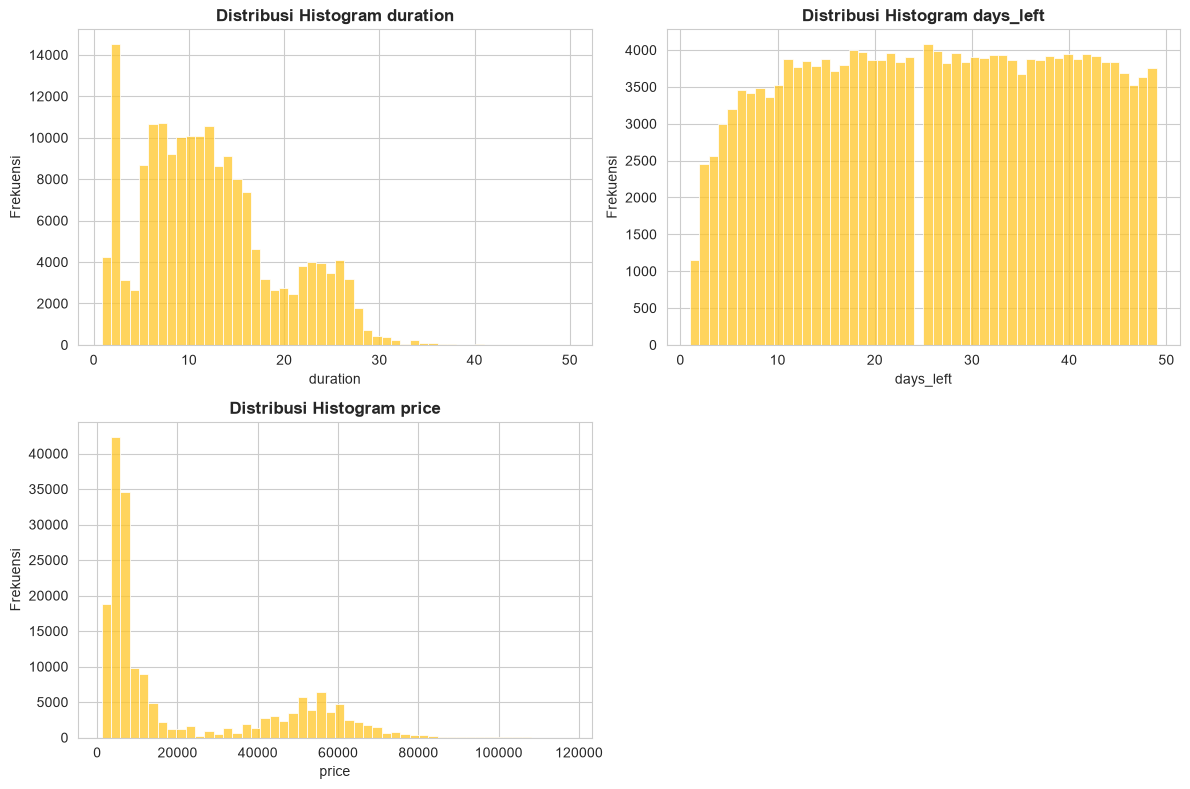

In [14]:
df_num = df.select_dtypes(include='number')
df_cat = df.select_dtypes(include='object')


num_cols = len(df_num.columns)

n_cols_grid = 2
n_rows_grid = (num_cols + n_cols_grid - 1) // n_cols_grid

fig, ax = plt.subplots(n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid))

ax_flat = ax.flatten() if num_cols > 1 else [ax]

for i, cols in enumerate(df_num.columns):
    sns.histplot(data=df_num, x=cols, ax=ax_flat[i], bins=50,color='#FFC627')
    ax_flat[i].set_title(f'Distribusi Histogram {cols}', fontsize=12, fontweight='bold')
    ax_flat[i].set_xlabel(cols)
    ax_flat[i].set_ylabel('Frekuensi')

for j in range(i + 1, len(ax_flat)):
    fig.delaxes(ax_flat[j])

plt.tight_layout()
plt.show()

**Interpretasi:**
1.    Sebagian besar penerbangan memiliki durasi sekitar 5–17 jam, dengan kelompok penerbangan lain pada kisaran 20–28 jam. Distribusi ini cenderung miring ke kanan karena jumlah penerbangan berdurasi sangat panjang relatif sedikit.
2.   Tiket rata rata dipesan pada rentang 10-49 hari, meskipun jumlah observasi lebih rendah pada hari-hari yang sangat dekat dengan keberangkatan
3.   Distribusi price menunjukkan dua kelompok harga yang menonjol, yaitu harga rendah dan harga tinggi.






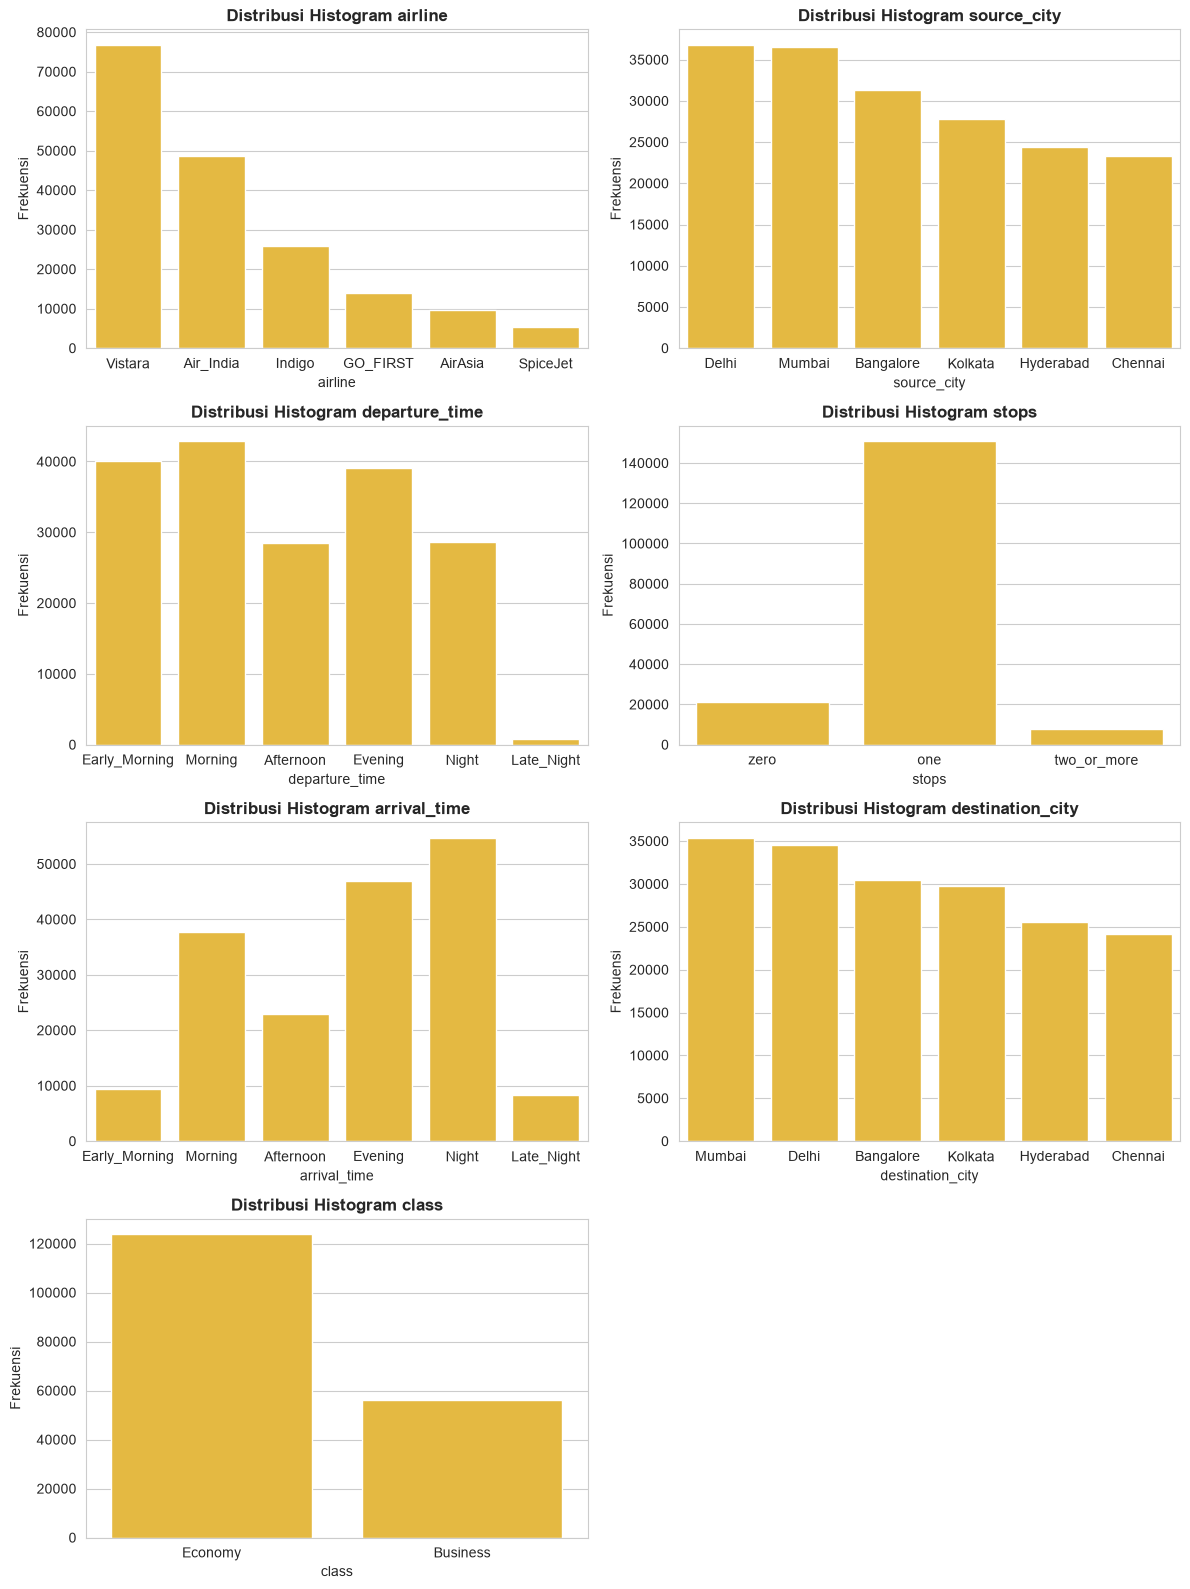

In [78]:
plot_cat = df_cat.drop(columns=['flight'], errors='ignore')
num_cols = len(plot_cat.columns)

custom_order = {
    'departure_time': ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night'],
    'arrival_time'  : ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night'],
    'stops'         : ['zero', 'one', 'two_or_more'],
}

n_cols_grid = 2
n_rows_grid = (num_cols + n_cols_grid - 1) // n_cols_grid

fig, ax = plt.subplots(n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid))

ax_flat = ax.flatten() if num_cols > 1 else [ax]

for i, cols in enumerate(plot_cat.columns):
    order = custom_order.get(cols, plot_cat[cols].value_counts().index)

    sns.countplot(data=plot_cat, x=cols, ax=ax_flat[i],color='#FFC627',order=order)
    ax_flat[i].set_title(f'Distribusi Histogram {cols}', fontsize=12, fontweight='bold')
    ax_flat[i].set_xlabel(cols)
    ax_flat[i].set_ylabel('Frekuensi')

for j in range(i + 1, len(ax_flat)):
    fig.delaxes(ax_flat[j])

plt.tight_layout()
plt.show()

Rata-rata Harga Berdasarkan Maskapai dan Kelas:
class          Business      Economy
airline                             
AirAsia             NaN  4091.664354
Air_India  47154.176574  7333.783796
GO_FIRST            NaN  5620.378146
Indigo              NaN  5321.817746
SpiceJet            NaN  6229.424214
Vistara    55567.219432  7805.071872


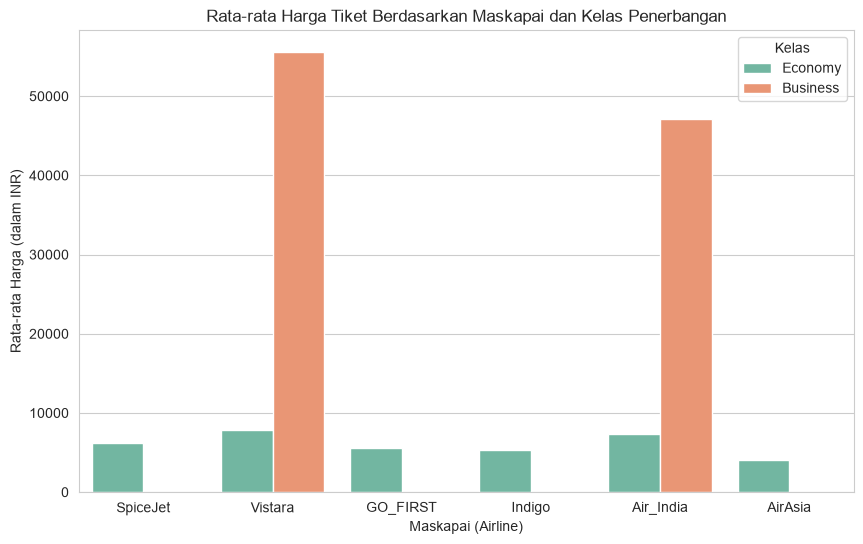

In [16]:
# Rata-rata harga berdasarkan maskapai dan kelas
airline_class_price = df.groupby(['airline', 'class'])['price'].mean().unstack()
print("Rata-rata Harga Berdasarkan Maskapai dan Kelas:")
print(airline_class_price)

# Visualisasi Bar Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='airline', y='price', hue='class', data=df, palette='Set2', errorbar=None)
plt.title('Rata-rata Harga Tiket Berdasarkan Maskapai dan Kelas Penerbangan')
plt.xlabel('Maskapai (Airline)')
plt.ylabel('Rata-rata Harga (dalam INR)')
plt.legend(title='Kelas')
plt.show()

**Interpretasi:**
1. Vistara merupakan maskapai dengan jumlah observasi terbesar, disusul Air India, sedangkan SpiceJet memiliki jumlah yang relatif lebih sedikit. dikarenakan vistara dan air india menyediakan layanan business yang tidak ada di maskapai lainnya
2. keenam kota utama memiliki cakupan data yang cukup besar, meskipun jumlah observasinya berbeda. Penerbangan pada waktu pagi, sore, dan malam lebih banyak ditemukan dibandingkan kategori waktu tertentu seperti late night
3. Berdasarkan jumlah transit, penerbangan dengan satu transit (one) mendominasi dataset, sedangkan penerbangan langsung (zero) dan dua transit atau lebih (two_or_more) memiliki jumlah observasi yang lebih kecil. Selain itu, kelas Economy memiliki observasi jauh lebih banyak dibandingkan Business.
4. Ketidakseimbangan ini penting diperhatikan karena model akan mempelajari pola dari kategori yang lebih sering muncul.
5. Monopoli dan Gap Harga Kelas Bisnis (Business Class Pricing):Layanan kelas Business hanya disediakan oleh dua maskapai saja, yaitu Vistara dan Air_India.   Rata-rata harga tiket kelas bisnis Vistara ( sekitar 55.477 INR) sedikit lebih mahal dibandingkan Air_India (sekitar 47.131 INR), dengan harga maksimal yang bisa menembus lebih dari 123.000 INR. Sebaliknya, maskapai seperti AirAsia, Indigo, GO_FIRST, dan SpiceJet murni hanya melayani kelas Economy dengan rata-rata harga di bawah 8.000 INR.

In [17]:
df = df.drop(columns='flight')

/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_64918/3112308180.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_cat = df.select_dtypes(include='object')


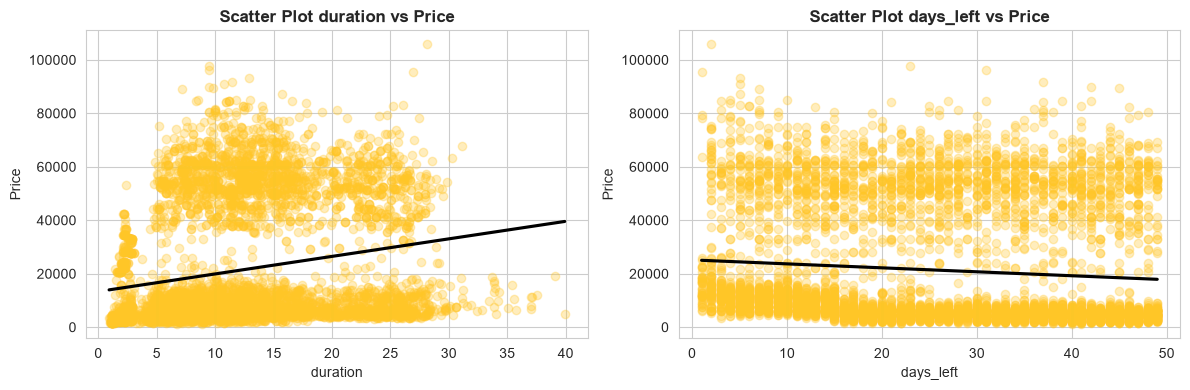

In [18]:
df_num = df.select_dtypes(include='number')
df_cat = df.select_dtypes(include='object')


plot_num = df_num.drop(columns=['price'])
num_cols = len(plot_num.columns)

n_cols_grid = 2
n_rows_grid = (num_cols + n_cols_grid - 1) // n_cols_grid

fig, ax = plt.subplots(n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid))

ax_flat = ax.flatten() if num_cols > 1 else [ax]

for i, cols in enumerate(plot_num.columns):
    sns.regplot(data=df.sample(min(6000, len(df)), random_state=42), ci=None, x=cols,y='price' , ax=ax_flat[i],color='#FFC627', line_kws={'color': 'black'},scatter_kws={'alpha': 0.3})
    ax_flat[i].set_xlabel(cols)
    ax_flat[i].set_ylabel('Price')
    ax_flat[i].set_title(f'Scatter Plot {cols} vs Price', fontsize=12, fontweight='bold')

for j in range(i + 1, len(ax_flat)):
    fig.delaxes(ax_flat[j])

plt.tight_layout()
plt.show()

**Interpretasi:**
1. Scatterplot menunjukkan kecenderungan hubungan positif antara duration dan price, yaitu harga tiket cenderung lebih tinggi pada penerbangan dengan durasi lebih panjang.
2. Sebaliknya, hubungan days_left dengan price menunjukkan kecenderungan negatif. Artinya, harga tiket secara umum cenderung lebih tinggi ketika waktu menuju keberangkatan semakin singkat.
3. Persebaran harga pada setiap nilai days_left masih cukup lebar. Hal ini menunjukkan bahwa waktu pemesanan perlu dianalisis bersama faktor lain, terutama kelas penerbangan, maskapai, dan rute. Kedua variabel berpotensi relevan untuk pemodelan, tetapi hubungan yang terlihat belum tentu bersifat linear atau sama pada seluruh segmen penerbangan.

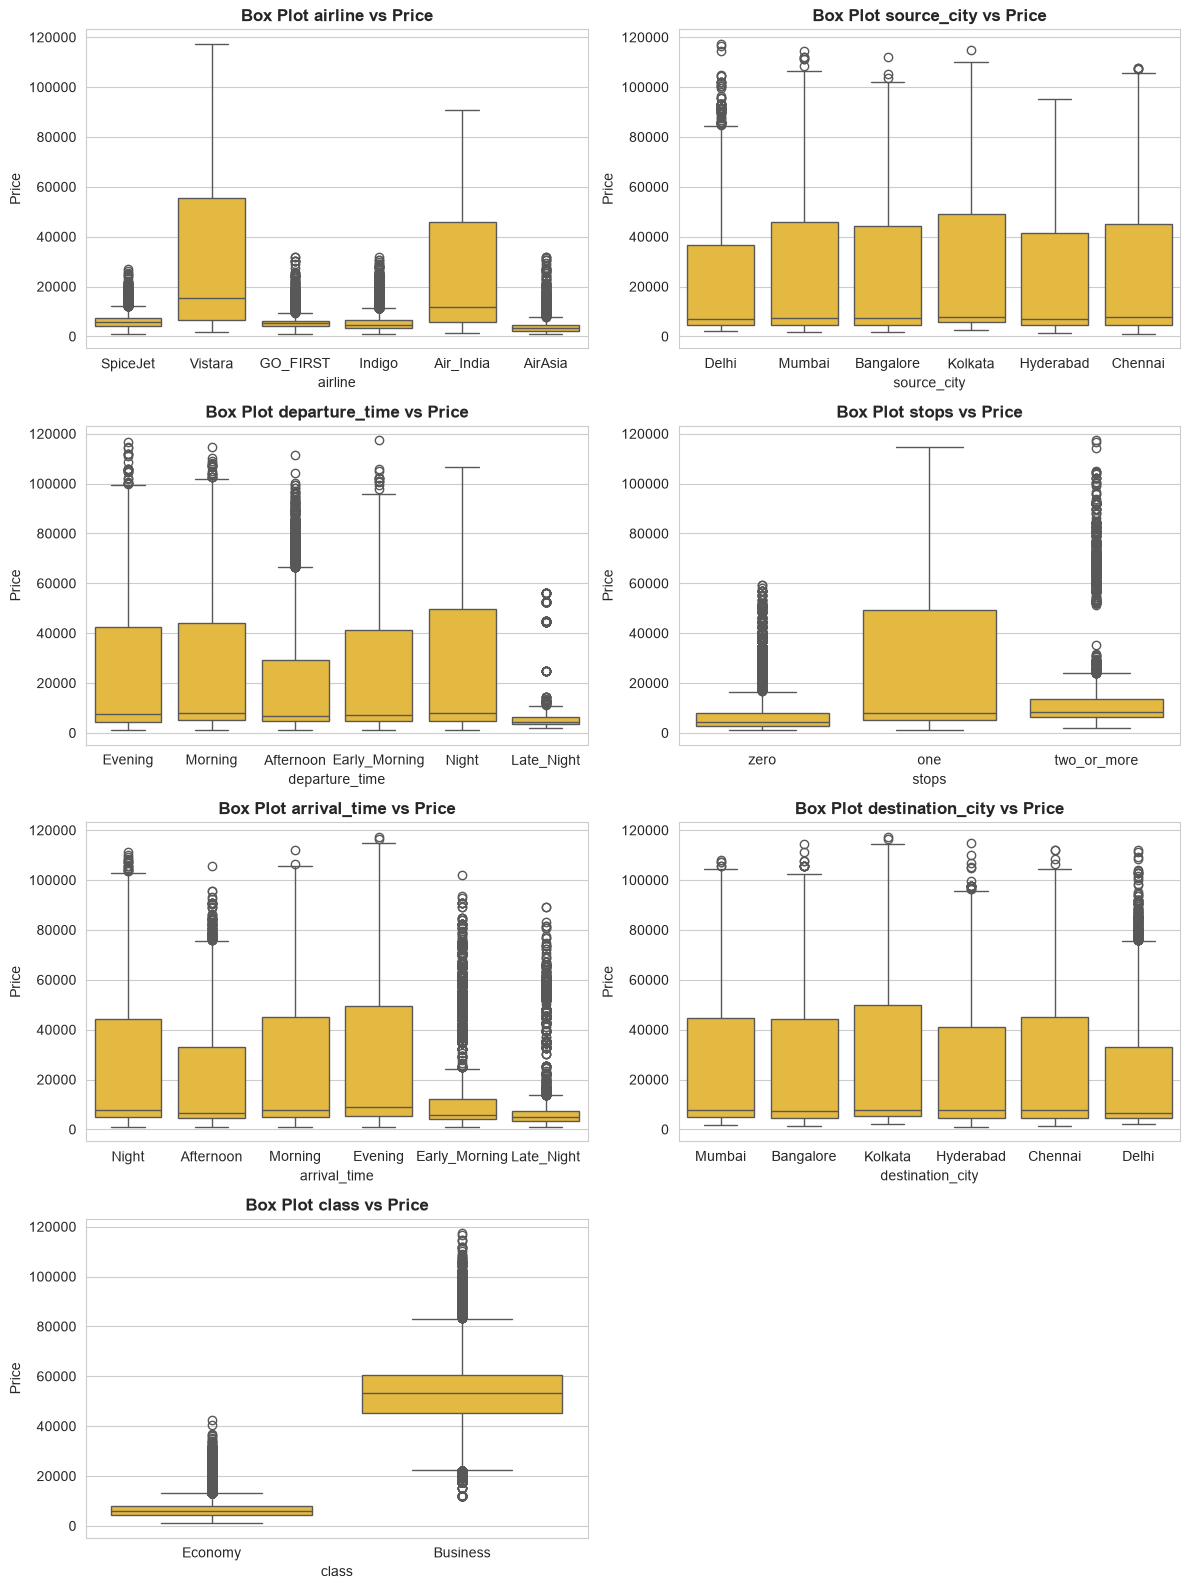

In [19]:
num_cols = len(df_cat.columns)

n_cols_grid = 2
n_rows_grid = (num_cols + n_cols_grid - 1) // n_cols_grid

fig, ax = plt.subplots(n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid))

ax_flat = ax.flatten() if num_cols > 1 else [ax]

for i, cols in enumerate(df_cat.columns):
    sns.boxplot(data=df, x=cols, y='price', ax=ax_flat[i],color='#FFC627')
    ax_flat[i].set_title(f'Box Plot {cols} vs Price', fontsize=12, fontweight='bold')
    ax_flat[i].set_xlabel(cols)
    ax_flat[i].set_ylabel('Price')

for j in range(i + 1, len(ax_flat)):
    fig.delaxes(ax_flat[j])

plt.tight_layout()
plt.show()

**Interpretasi:**
Berdasarkan keseluruhan boxplot, perbedaan distribusi harga paling jelas terlihat pada variabel class dan airline. Kelas Business memiliki median harga jauh lebih tinggi dibandingkan Economy, sedangkan Vistara dan Air India menunjukkan rentang harga yang lebih luas dibandingkan maskapai lainnya.



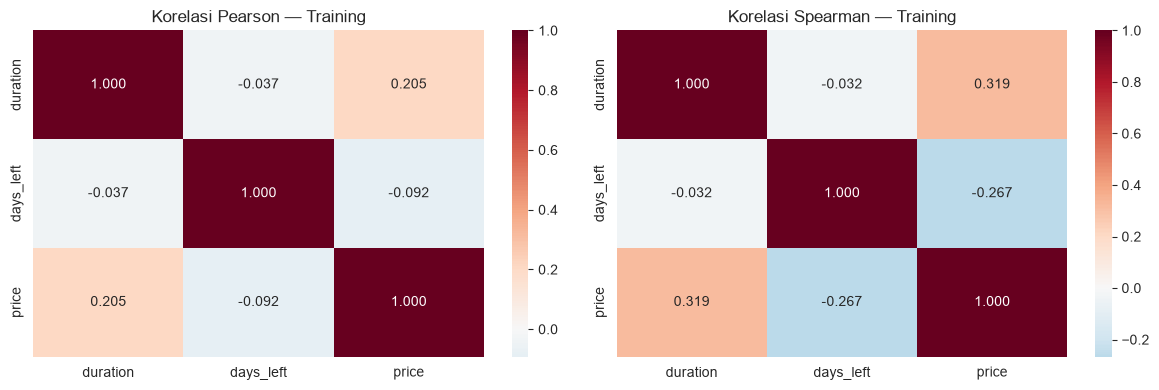

Korelasi per kelas:
Business {'duration': 0.2351503312948136, 'days_left': -0.09223366830567938, 'price': 1.0}
Economy {'duration': 0.2890404441836434, 'days_left': -0.5596670578266193, 'price': 1.0}


In [20]:
corr_cols = ['duration', 'days_left', 'price']
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, method in zip(ax, ['pearson', 'spearman']):
    sns.heatmap(df[corr_cols].corr(method=method), annot=True, fmt='.3f',
                cmap='RdBu_r', center=0, ax=a)
    a.set_title(f'Korelasi {method.title()} — Training')
plt.tight_layout()
plt.show()

print('Korelasi per kelas:')
for kelas, part in df.groupby('class'):
    print(kelas, part[corr_cols].corr().price.to_dict())

**Interpretasi:**
1. Hasil korelasi Pearson menunjukkan hubungan positif yang lemah antara duration dan price sebesar 0,205, serta hubungan negatif yang sangat lemah antara days_left dan price sebesar -0,092.
2. Sementara itu, korelasi Spearman menunjukkan hubungan yang lebih jelas, yaitu sebesar 0,319 untuk duration terhadap price dan -0,267 untuk days_left terhadap price. Perbedaan ini mengindikasikan bahwa hubungan antarvariabel kemungkinan tidak sepenuhnya linear.
3. Analisis berdasarkan kelas juga menunjukkan adanya perbedaan pola. Pada kelas Business, korelasi Pearson antara days_left dan price sekitar -0,092, sedangkan pada Economy sekitar -0,560.

                    count      mean   median       std
airline   class                                       
Air_India Business  19833  47154.18  49613.0  10447.44
          Economy   28746   7333.78   6082.0   4012.45
Vistara   Business  36403  55567.22  56588.0  13268.88
          Economy   40433   7805.07   6461.0   3855.97
Sel sebanding: 475 | Equal-cell mean/median gap: {'mean': 3083.34, 'median': 410.0}


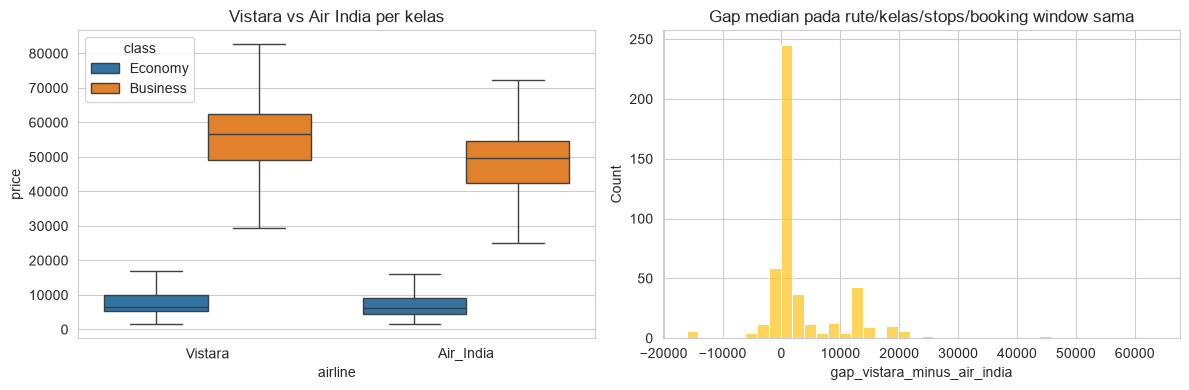

In [21]:
compare = df[df.airline.isin(['Vistara', 'Air_India'])].copy()
print(compare.groupby(['airline', 'class']).price.agg(['count', 'mean', 'median', 'std']).round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=compare, x='airline', y='price', hue='class', showfliers=False, ax=ax[0]) 
ax[0].set_title('Vistara vs Air India per kelas')
compare['days_bucket'] = pd.cut(compare.days_left, [-1, 7, 14, 30, 60], labels=['0–7', '8–14', '15–30', '31–60'])



matched = compare.pivot_table(index=['source_city','destination_city','class','stops','days_bucket'], columns='airline', values='price', aggfunc='median', observed=True).dropna()
matched['gap_vistara_minus_air_india'] = matched.Vistara - matched.Air_India

print('Sel sebanding:', len(matched), '| Equal-cell mean/median gap:', matched.gap_vistara_minus_air_india.agg(['mean','median']).round(2).to_dict())

sns.histplot(matched.gap_vistara_minus_air_india, bins=40, color='#FFC627', ax=ax[1])
ax[1].set_title('Gap median pada rute/kelas/stops/booking window sama')
plt.tight_layout() 
plt.show()

**Interpretasi:**
Hasil perbandingan menunjukkan bahwa Vistara memiliki median harga lebih tinggi dibandingkan Air India pada kedua kelas penerbangan. Pada kelas Business, median harga Vistara sebesar 56.588, sedangkan Air India sebesar 49.613. Pada kelas Economy, median harga Vistara sebesar 6.461 dan Air India sebesar 6.082. Temuan ini menunjukkan adanya indikasi premi harga Vistara dibandingkan Air India, khususnya pada kelas Business. Namun, hasil tersebut merupakan perbandingan observasional dan belum membuktikan bahwa perbedaan harga disebabkan oleh identitas maskapai saja.

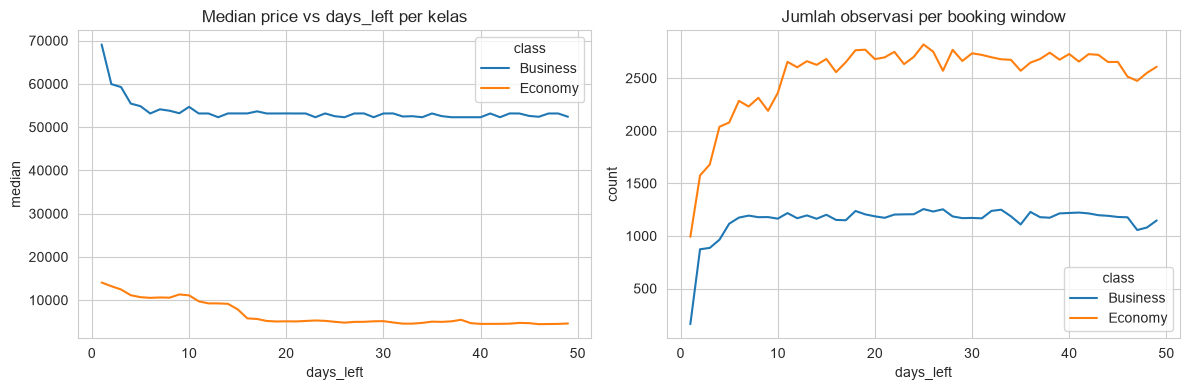

In [22]:
daily = df.groupby(['days_left','class']).price.agg(['count','mean','median']).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=daily, x='days_left', y='median', hue='class', ax=ax[0])
ax[0].set_title('Median price vs days_left per kelas')
sns.lineplot(data=daily, x='days_left', y='count', hue='class', ax=ax[1])
ax[1].set_title('Jumlah observasi per booking window')
plt.tight_layout()
plt.show()

                    count      mean   median
class    window                             
Business 0–7 hari    6367  56850.88  56081.0
         >7 hari    49869  52057.45  53152.0
Economy  0–7 hari   12875  11682.49  11310.0
         >7 hari   110979   5983.47   5378.0
Interaksi airline × class (median):
class      Business  Economy
airline                     
AirAsia         NaN   3175.0
Air_India   49613.0   6082.0
GO_FIRST        NaN   5303.0
Indigo          NaN   4453.0
SpiceJet        NaN   5654.0
Vistara     56588.0   6461.0
Business minus Economy (hanya tersedia di maskapai tertentu):
airline
Air_India    43531.0
Vistara      50127.0
dtype: float64


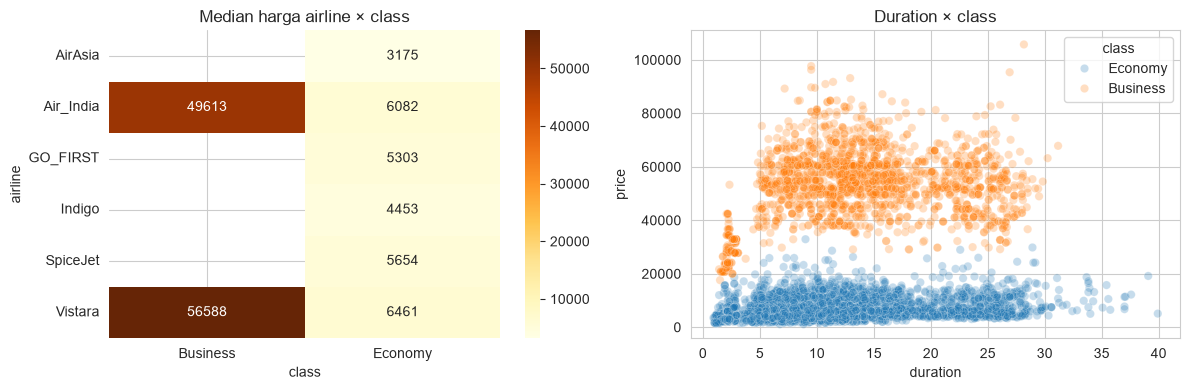

In [23]:

window = df.assign(window=np.where(df.days_left <= 7, '0–7 hari', '>7 hari'))
print(window.groupby(['class','window']).price.agg(['count','mean','median']).round(2))
interaction = df.groupby(['airline','class']).price.median().unstack()

print('Interaksi airline × class (median):')
print(interaction.round(2))
print('Business minus Economy (hanya tersedia di maskapai tertentu):')
print((interaction.Business - interaction.Economy).dropna().round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(interaction, annot=True, fmt='.0f', cmap='YlOrBr', ax=ax[0])
sns.scatterplot(data=df.sample(min(6000,len(df)),random_state=42), x='duration', y='price', hue='class', alpha=.25, ax=ax[1])

ax[0].set_title('Median harga airline × class')
ax[1].set_title('Duration × class')
plt.tight_layout()
plt.show()

**Interpretasi:**
1. Grafik median harga berdasarkan days_left memperlihatkan bahwa harga tiket pada kedua kelas cenderung lebih tinggi ketika tanggal keberangkatan semakin dekat. Pola ini lebih menonjol pada kelas Economy, terutama pada periode sekitar dua minggu sebelum keberangkatan.
2. Scatterplot durasi terhadap harga juga menunjukkan pemisahan yang jelas antara Economy dan Business. Penerbangan dengan durasi yang sama dapat memiliki harga sangat berbeda tergantung kelasnya.
3. Berdasarkan analisis grafik diatas,di mana harga kelas Economy dan Business mengalami lonjakan eksponensial drastis pada hari-hari terakhir menjelang keberangkatan. Kelas Economy meroket dari kisaran 5.000 INR menjadi di atas 14.000 INR, sementara kelas Business melonjak hingga menembus di atas 65.000 INR pada 5 hari terakhir. Oleh karena itu, rentang waktu 15 hingga 49 hari sebelum keberangkatan merupakan sweet spot atau zona aman untuk mendapatkan harga tiket yang paling stabil dan ekonomis.

In [24]:
eda_data = train_raw.copy()
eda_data['route'] = eda_data.source_city + ' → ' + eda_data.destination_city
eda_data['booking_window'] = pd.cut(eda_data.days_left, [0,3,7,14,30,49],
    labels=['1–3','4–7','8–14','15–30','31–49'])
eda_data['duration_band'] = pd.cut(eda_data.duration, [0,3,6,12,24,50],
    labels=['≤3 jam','3–6 jam','6–12 jam','12–24 jam','24–50 jam'])
assert eda_data.index.equals(train_raw.index)
assert eda_data.index.intersection(val_raw.index).empty
assert eda_data.index.intersection(test_raw.index).empty
assert eda_data[['booking_window','duration_band']].notna().all().all()

In [25]:
eda_min_cell_n = 3
eda_features = [c for c in train_raw.columns if c not in ['price','flight']]
eda_signature = pd.util.hash_pandas_object(eda_data[eda_features],index=False)
eda_ambiguity = eda_data.assign(input_group=eda_signature).groupby('input_group').price.agg(['size','nunique','min','max'])
eda_ambiguous = eda_ambiguity[eda_ambiguity['nunique'] > 1]
print('Training observations:',len(eda_data),'| Flight codes:',eda_data.flight.nunique(),
      '| Directed routes:',eda_data.route.nunique())
print('Input groups with multiple prices:',len(eda_ambiguous),
      '| Rows in those groups:',int(eda_ambiguous['size'].sum()))
print('Duration range:',eda_data.duration.agg(['min','max']).to_dict(),
      '| Days_left:',eda_data.days_left.agg(['min','max']).to_dict())

Training observations: 180090 | Flight codes: 1544 | Directed routes: 30
Input groups with multiple prices: 2930 | Rows in those groups: 5882
Duration range: {'min': 0.83, 'max': 49.83} | Days_left: {'min': 1, 'max': 49}


class      Economy  Business
airline                     
AirAsia       9656         0
Air_India    28746     19833
GO_FIRST     13865         0
Indigo       25843         0
SpiceJet      5311         0
Vistara      40433     36403


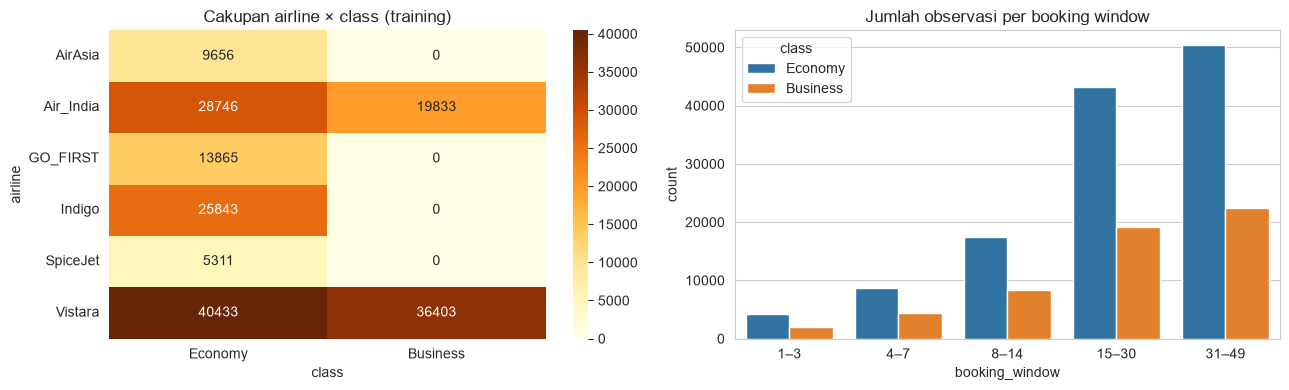

Window memiliki lebar berbeda: jumlah baris bukan frekuensi permintaan/penjualan.


In [26]:
eda_support = pd.crosstab(eda_data.airline,eda_data['class']).reindex(columns=['Economy','Business'],fill_value=0)
print(eda_support.to_string())

fig, eda_ax = plt.subplots(1,2,figsize=(13,4))
sns.heatmap(eda_support,annot=True,fmt='d',cmap='YlOrBr',ax=eda_ax[0])
eda_ax[0].set_title('Cakupan airline × class (training)')

sns.countplot(data=eda_data,x='booking_window',hue='class',ax=eda_ax[1])
eda_ax[1].set_title('Jumlah observasi per booking window')
plt.tight_layout()
plt.show()

print('Window memiliki lebar berbeda: jumlah baris bukan frekuensi permintaan/penjualan.')

**Interpretasi:** Distribusi observasi tidak merata pada kombinasi maskapai dan kelas. Kelas Business hanya tersedia pada Vistara dan Air India, sedangkan Economy mencakup seluruh maskapai. Selain itu, jumlah observasi pada periode pemesanan yang jauh dari keberangkatan lebih besar dibandingkan periode yang sangat dekat. Perbedaan ini juga dipengaruhi oleh lebar interval booking window yang tidak sama.

               n      mean   median      p10      p25      p75      p90      IQR  IQR_over_median
class                                                                                            
Business   56236  52600.15  53164.0  36577.0  45185.0  60396.0  67635.0  15211.0             0.29
Economy   123854   6575.90   5772.0   2862.0   4173.0   7761.0  11786.0   3588.0             0.62
Rasio median Business/Economy agregat: 9.21x


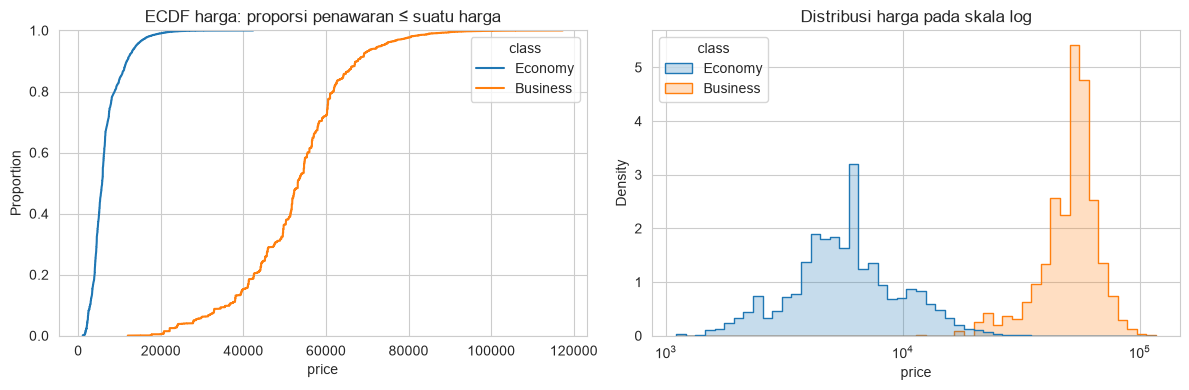

In [27]:
eda_distribution = eda_data.groupby('class').price.agg(
    n='size',mean='mean',median='median',p10=lambda x:x.quantile(.10),
    p25=lambda x:x.quantile(.25),p75=lambda x:x.quantile(.75),p90=lambda x:x.quantile(.90))
eda_distribution['IQR'] = eda_distribution.p75-eda_distribution.p25
eda_distribution['IQR_over_median'] = eda_distribution.IQR/eda_distribution['median']
print(eda_distribution.round(2).to_string())

eda_class_ratio = eda_distribution.loc['Business','median']/eda_distribution.loc['Economy','median']
print(f'Rasio median Business/Economy agregat: {eda_class_ratio:.2f}x')


fig, eda_ax = plt.subplots(1,2,figsize=(12,4))
sns.ecdfplot(data=eda_data,x='price',hue='class',ax=eda_ax[0])
eda_ax[0].set_title('ECDF harga: proporsi penawaran ≤ suatu harga')
sns.histplot(data=eda_data,x='price',hue='class',element='step',stat='density',common_norm=False,log_scale=True,bins=50,ax=eda_ax[1])

eda_ax[1].set_title('Distribusi harga pada skala log')
plt.tight_layout()
plt.show()

**Interpretasi:** Analisis distribusi harga berdasarkan kelas menunjukkan perbedaan yang sangat besar antara Economy dan Business. Median harga Business sebesar 53.164, sedangkan Economy sebesar 5.772, dengan rasio median sekitar 9,21 kali.Berdasarkan rasio IQR terhadap median, kelas Economy memiliki dispersi relatif lebih tinggi, yaitu sekitar 0,62 dibandingkan Business sebesar 0,29. Artinya, meskipun harga Business lebih tinggi secara absolut, variasi harga Economy relatif lebih besar terhadap median harganya.

Temuan ini memperkuat bahwa class merupakan variabel segmentasi utama dan perlu diperhitungkan dalam analisis harga maupun evaluasi model.

Reference class mix: {'Economy': 0.5516, 'Business': 0.4484}
           raw_mean  class_standardized_mean  business_share_pct
airline                                                         
Air_India  23590.97                 25189.22               40.83
Vistara    30433.60                 29221.59               47.38
Raw mean gap Vistara−Air India: 6,842.63 class-standardized gap: 4,032.37
Median per kelas:
class      Business  Economy
airline                     
Air_India   49613.0   6082.0
Vistara     56588.0   6461.0


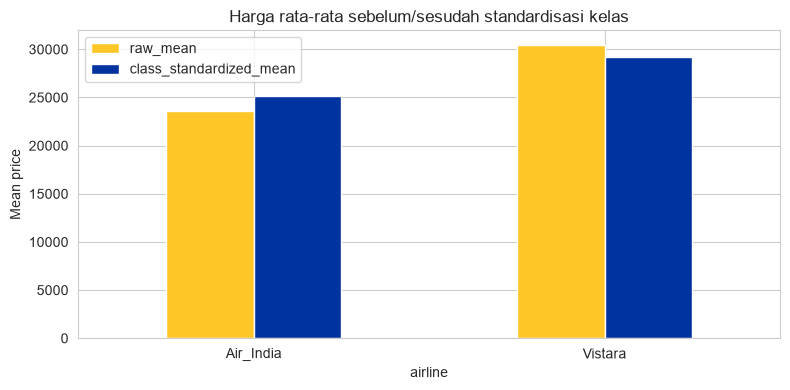

In [28]:
eda_airlines = eda_data[eda_data.airline.isin(['Vistara','Air_India'])].copy()
eda_airline_class = eda_airlines.groupby(['airline','class']).price.agg(['size','mean','median'])
eda_class_means = eda_airline_class['mean'].unstack()
eda_class_shares = pd.crosstab(eda_airlines.airline,eda_airlines['class'],normalize='index')


eda_reference_mix = eda_airlines['class'].value_counts(normalize=True)
eda_standardized_mean = eda_class_means.mul(eda_reference_mix,axis=1).sum(axis=1)
eda_composition = pd.DataFrame({'raw_mean':eda_airlines.groupby('airline').price.mean(),
    'class_standardized_mean':eda_standardized_mean,
    'business_share_pct':100*eda_class_shares['Business']})
print('Reference class mix:',eda_reference_mix.round(4).to_dict())
print(eda_composition.round(2).to_string())


eda_raw_gap = float(eda_composition.loc['Vistara','raw_mean']-eda_composition.loc['Air_India','raw_mean'])
eda_standardized_gap = float(eda_standardized_mean.Vistara-eda_standardized_mean.Air_India)
print(f'Raw mean gap Vistara−Air India: {eda_raw_gap:,.2f} class-standardized gap: {eda_standardized_gap:,.2f}')
print('Median per kelas:')
print(eda_airline_class['median'].unstack().round(2).to_string())
eda_composition[['raw_mean','class_standardized_mean']].plot.bar(color=['#FFC627','#0033A0'],figsize=(8,4),rot=0)
plt.ylabel('Mean price')
plt.title('Harga rata-rata sebelum/sesudah standardisasi kelas')
plt.tight_layout()
plt.show()

**Interpretasi:**
1.  Sebagian perbedaan harga rata-rata antara Vistara dan Air India berkaitan dengan perbedaan komposisi kelas penerbangan. Vistara memiliki proporsi Business lebih besar dibandingkan Air India.
2. Namun, selisih harga tetap terlihat setelah standardisasi kelas. Artinya, perbedaan komposisi kelas bukan satu-satunya penjelasan karakteristik lain seperti rute, durasi, waktu pemesanan, dan jumlah transit masih perlu dipertimbangkan.

In [29]:
def eda_route_bootstrap_ci(data,value_col,stat='median',draws=500,seed=42):
    """Resample seluruh rute (bukan baris individual) interval sensitivitas sampel."""
    route_arrays = [g[value_col].to_numpy() for _,g in data.groupby('route',observed=True)]
    if len(route_arrays)<5: return (np.nan,np.nan)
    rng = np.random.default_rng(seed)
    fn = np.median if stat=='median' else np.mean
    sampled = [fn(np.concatenate([route_arrays[j] for j in rng.integers(0,len(route_arrays),len(route_arrays))]))
               for _ in range(draws)]
    return tuple(np.quantile(sampled,[.025,.975]))

In [30]:
def eda_match_cells(data,keys,comparison,level_a,level_b,min_n=3):
    """Median harga A−B per sel hanya sel dengan >=min_n baris di kedua sisi."""
    grouped = data.groupby(keys+[comparison],observed=True).price.agg(n='size',median='median').reset_index()
    a = grouped[grouped[comparison]==level_a].set_index(keys)[['n','median']]
    b = grouped[grouped[comparison]==level_b].set_index(keys)[['n','median']]
    matched = a.join(b,lsuffix='_a',rsuffix='_b',how='inner')
    matched = matched[(matched.n_a>=min_n)&(matched.n_b>=min_n)].copy()
    matched['gap'] = matched.median_a-matched.median_b
    matched['pct_gap'] = 100*(matched.median_a/matched.median_b-1)
    return matched.reset_index()


                    spec    class  cells  routes  row_coverage_pct  mean_cell_gap  median_cell_gap  median_pct_gap  ci_low  ci_high
Route/class/stops/window Business    233      30             98.79        6976.18           4167.0            7.36   112.0  9322.00
Route/class/stops/window  Economy    299      30             97.73         668.87            266.0            4.20    19.0   615.26
   + jam & duration band Business   1134      30             59.41        7237.50           7840.0           15.82  1405.5 10782.42
   + jam & duration band  Economy   1366      30             58.53         297.73            297.0            4.64    74.0   565.00


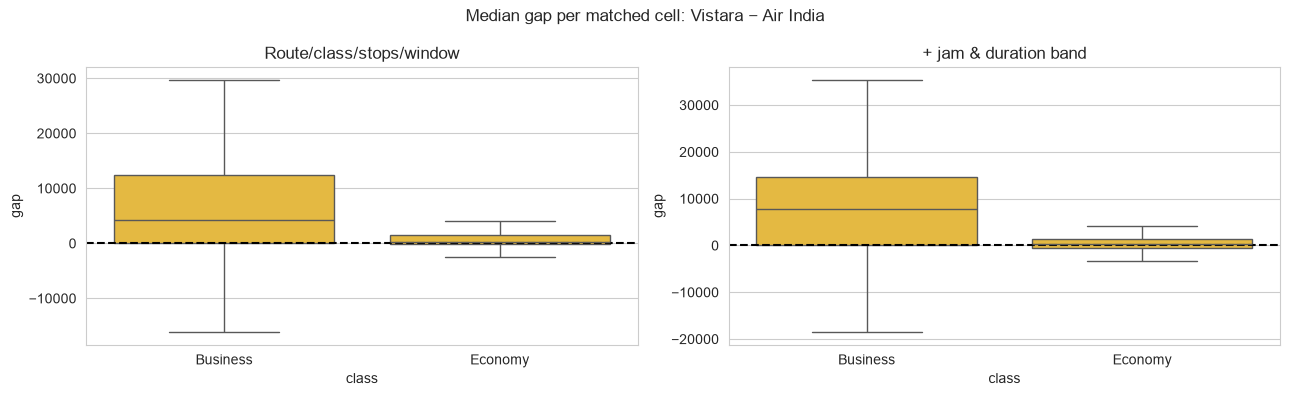

Bobot sama per sel bukan rata-rata gap berbobot penumpang/penjualan.


In [31]:
eda_specs = {
    'Route/class/stops/window':['route','class','stops','booking_window'],
    '+ jam & duration band':['route','class','stops','booking_window','departure_time','arrival_time','duration_band']}
eda_airline_matched = {}
eda_premium_rows = []

for eda_spec,eda_keys in eda_specs.items():
    eda_match = eda_match_cells(eda_airlines,eda_keys,'airline','Vistara','Air_India',eda_min_cell_n)
    eda_airline_matched[eda_spec] = eda_match
    for eda_class,eda_part in eda_match.groupby('class',observed=True):
        eda_eligible = eda_airlines[eda_airlines['class']==eda_class]
        eda_ci = eda_route_bootstrap_ci(eda_part,'gap')
        eda_premium_rows.append({'spec':eda_spec,'class':eda_class,'cells':len(eda_part),
            'routes':eda_part.route.nunique(),'row_coverage_pct':100*(eda_part.n_a.sum()+eda_part.n_b.sum())/len(eda_eligible),
            'mean_cell_gap':eda_part.gap.mean(),'median_cell_gap':eda_part.gap.median(),
            'median_pct_gap':eda_part.pct_gap.median(),'ci_low':eda_ci[0],'ci_high':eda_ci[1]})
        
        
        
eda_premium_summary = pd.DataFrame(eda_premium_rows)
print(eda_premium_summary.round(2).to_string(index=False))
fig, eda_ax = plt.subplots(1,2,figsize=(13,4))

for eda_a,(eda_spec,eda_part) in zip(eda_ax,eda_airline_matched.items()):
    sns.boxplot(data=eda_part,x='class',y='gap',showfliers=False,color='#FFC627',ax=eda_a)
    eda_a.axhline(0,color='black',linestyle='--')
    eda_a.set_title(eda_spec)
    
plt.suptitle('Median gap per matched cell: Vistara − Air India')
plt.tight_layout()
plt.show()

print('Bobot sama per sel bukan rata-rata gap berbobot penumpang/penjualan.')

**Interpretasi:** Vistara cenderung memiliki harga lebih tinggi pada segmen yang dapat dibandingkan, terutama pada kelas Business. Namun, besarnya selisih berubah sesuai kriteria pencocokan dan cakupan observasi yang tersedia.

   class  flight_itineraries  routes  matched_row_coverage_pct  median_near_minus_far  median_pct_premium  ci_low_pct  ci_high_pct
Business                 990      30                     70.74                  560.0                1.66        0.00         3.69
 Economy                1818      30                     52.11                 5660.0              127.48      116.98       138.66
Raw distribution per window (belum matching):
                             n   median      p25       p75
class    booking_window                                   
Business 1–3              1920  59948.0  51699.5  71792.00
         4–7              4447  54608.0  45693.0  62056.00
         8–14             8264  53209.0  45257.0  60508.00
         15–30           19181  53152.0  45097.0  60260.00
         31–49           22424  52586.0  44432.0  60232.00
Economy  1–3              4245  13128.0   9904.0  17304.00
         4–7              8630  10680.0   7584.0  12990.00
         8–14            17406

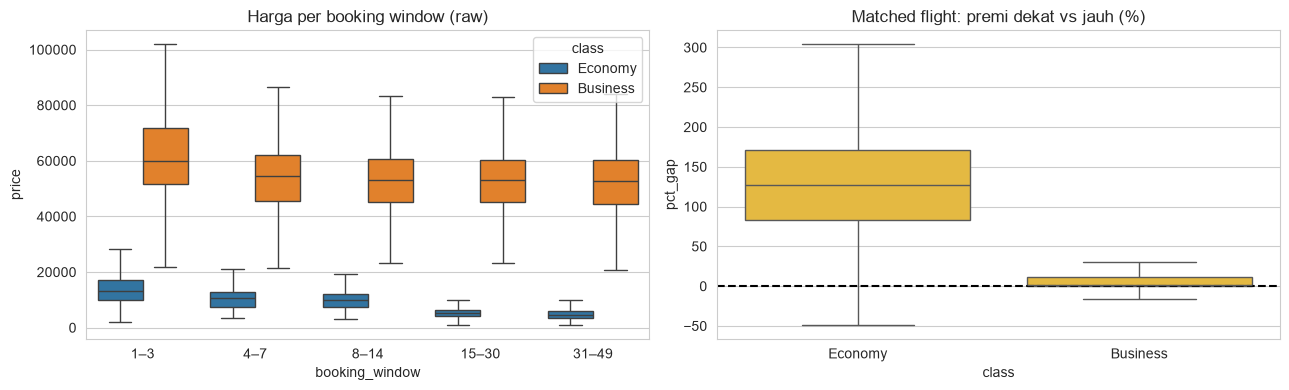

In [32]:
eda_data['horizon'] = np.where(eda_data.days_left<=7,'1–7 hari',np.where(eda_data.days_left>=31,'31–49 hari','Tengah'))
eda_horizon_data = eda_data[eda_data.horizon!='Tengah']

eda_flight_keys = ['route','flight','class','stops','departure_time','arrival_time']
eda_flight_pairs = eda_match_cells(eda_horizon_data,eda_flight_keys,'horizon','1–7 hari','31–49 hari',min_n=3)
eda_booking_rows = []

for eda_class,eda_part in eda_flight_pairs.groupby('class',observed=True):
    eda_ci = eda_route_bootstrap_ci(eda_part,'pct_gap')
    eda_class_horizons = eda_horizon_data[eda_horizon_data['class']==eda_class]
    eda_booking_rows.append({'class':eda_class,'flight_itineraries':len(eda_part),
        'routes':eda_part.route.nunique(),
        'matched_row_coverage_pct':100*(eda_part.n_a.sum()+eda_part.n_b.sum())/len(eda_class_horizons),
        'median_near_minus_far':eda_part.gap.median(),
        'median_pct_premium':eda_part.pct_gap.median(),'ci_low_pct':eda_ci[0],'ci_high_pct':eda_ci[1]})
eda_booking_summary = pd.DataFrame(eda_booking_rows)
print(eda_booking_summary.round(2).to_string(index=False))
eda_daily_window = eda_data.groupby(['class','booking_window'],observed=True).price.agg(n='size',median='median',p25=lambda x:x.quantile(.25),p75=lambda x:x.quantile(.75))
print('Raw distribution per window (belum matching):')
print(eda_daily_window.round(2).to_string())

fig, eda_ax = plt.subplots(1,2,figsize=(13,4))

sns.boxplot(data=eda_data,x='booking_window',y='price',hue='class',showfliers=False,ax=eda_ax[0])
eda_ax[0].set_title('Harga per booking window (raw)')

sns.boxplot(data=eda_flight_pairs,x='class',y='pct_gap',showfliers=False,color='#FFC627',ax=eda_ax[1])
eda_ax[1].axhline(0,color='black',linestyle='--')
eda_ax[1].set_title('Matched flight: premi dekat vs jauh (%)')
plt.tight_layout()
plt.show()

**Interpretasi:**
1. Perbandingan harga berdasarkan booking window menunjukkan bahwa tiket yang diamati pada periode 1–3 hari sebelum keberangkatan memiliki median harga lebih tinggi dibandingkan periode pemesanan yang lebih jauh.
2. Pada kelas Economy, median harga periode 1–3 hari sebesar 14.128, kemudian menurun hingga 4.700 pada periode 31–49 hari. Pada Business, median harga turun dari 59.948 menjadi 52.586 pada periode yang sama. Median premi harga dekat keberangkatan pada penerbangan yang dicocokkan mencapai sekitar 127,48% untuk Economy, sedangkan Business sekitar 1,66%.
3. Temuan ini menunjukkan bahwa hubungan waktu pemesanan dengan harga sangat bergantung pada kelas penerbangan

Raw medians:
                           n  median_price  median_hours
class    stops                                          
Business one           50799       54608.0         13.83
         two_or_more     639       68743.0         12.42
         zero           4798       27864.0          2.25
Economy  one          100077        5934.0         11.25
         two_or_more    7329        7963.0         12.83
         zero          16448        3531.0          2.25
Matched one-stop minus nonstop:
   class  matched_cells  routes  median_gap_one_minus_zero  median_pct_gap  ci_low  ci_high
Business            330      25                    25345.0           97.27 21918.0 31712.78
 Economy            961      29                     1742.0           48.89  1266.0  2307.75


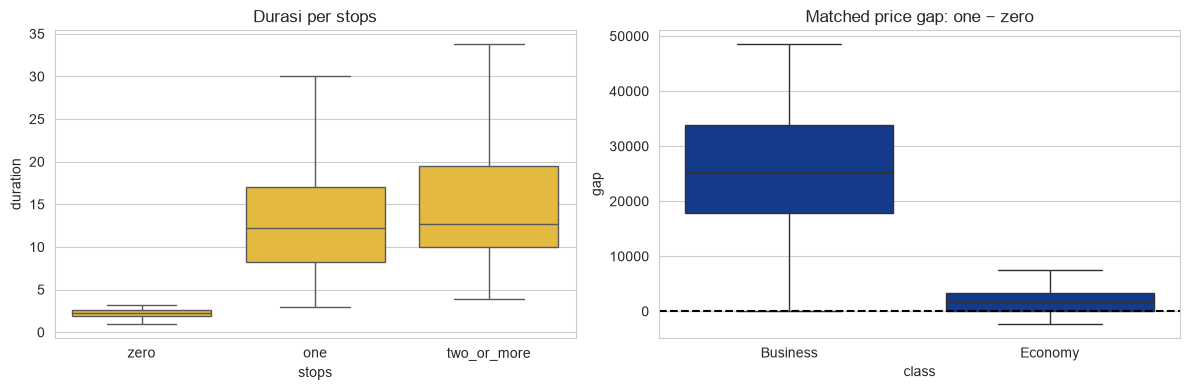

In [33]:
eda_stops_raw = eda_data.groupby(['class','stops']).agg(n=('price','size'),median_price=('price','median'),median_hours=('duration','median'))
print('Raw medians:')
print(eda_stops_raw.round(2).to_string())

eda_stops_keys = ['route','class','airline','booking_window','departure_time']
eda_stop_pairs = eda_match_cells(eda_data,eda_stops_keys,'stops','one','zero',min_n=5)
eda_stop_rows=[]

for eda_class,eda_part in eda_stop_pairs.groupby('class',observed=True):
    eda_ci=eda_route_bootstrap_ci(eda_part,'gap')
    eda_stop_rows.append({'class':eda_class,'matched_cells':len(eda_part),
        'routes':eda_part.route.nunique(),'median_gap_one_minus_zero':eda_part.gap.median(),
        'median_pct_gap':eda_part.pct_gap.median(),'ci_low':eda_ci[0],'ci_high':eda_ci[1]})
eda_stop_summary=pd.DataFrame(eda_stop_rows)
print('Matched one-stop minus nonstop:')
print(eda_stop_summary.round(2).to_string(index=False))

fig,eda_ax=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=eda_data,x='stops',y='duration',order=['zero','one','two_or_more'], showfliers=False,color='#FFC627',ax=eda_ax[0])
eda_ax[0].set_title('Durasi per stops')

sns.boxplot(data=eda_stop_pairs,x='class',y='gap',showfliers=False,color='#0033A0',ax=eda_ax[1])
eda_ax[1].axhline(0,color='black',linestyle='--')
eda_ax[1].set_title('Matched price gap: one − zero')
plt.tight_layout()
plt.show()

**Interpretasi:**
1. Setelah dilakukan pencocokan berdasarkan karakteristik yang tersedia, median selisih harga satu transit dibandingkan nonstop tetap positif, yaitu sekitar 25.345 pada kelas Business dan 1.742 pada Economy.
2. Satu transit tidak selalu menjadi pilihan yang lebih murah. Namun, hasil tersebut perlu dibaca sesuai cakupan matched-cell yang tersedia dan tidak dapat digeneralisasikan ke seluruh rute penerbangan.

             comparison      n  pearson_within_centered
                Agregat 180090                   0.2047
            Dalam kelas 180090                   0.2122
Dalam itinerary segment 171622                  -0.0430


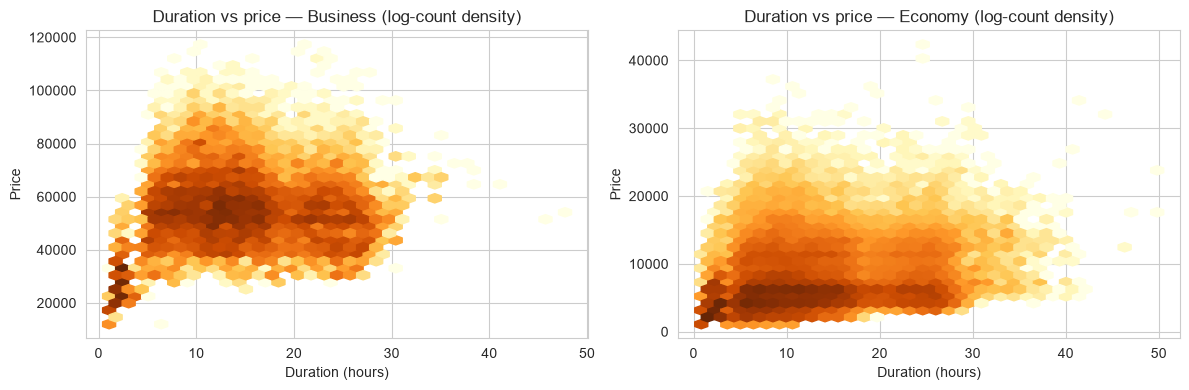

In [34]:
eda_duration_rows=[]
for eda_label,eda_keys in [('Agregat',[]),('Dalam kelas',['class']),
    ('Dalam itinerary segment',['class','airline','route','stops','booking_window'])]:
    if eda_keys:
        eda_group=eda_data.groupby(eda_keys,observed=True)
        eda_n=eda_group.price.transform('size')
        eda_ok=eda_n>=20
        eda_duration_centered=eda_data.duration-eda_group.duration.transform('mean')
        eda_price_centered=eda_data.price-eda_group.price.transform('mean')
    else:
        eda_ok=pd.Series(True,index=eda_data.index)
        eda_duration_centered=eda_data.duration-eda_data.duration.mean()
        eda_price_centered=eda_data.price-eda_data.price.mean()
    eda_r=eda_duration_centered[eda_ok].corr(eda_price_centered[eda_ok])
    eda_duration_rows.append({'comparison':eda_label,'n':int(eda_ok.sum()),'pearson_within_centered':eda_r})
eda_duration_summary=pd.DataFrame(eda_duration_rows)
print(eda_duration_summary.round(4).to_string(index=False))

fig,eda_ax=plt.subplots(1,2,figsize=(12,4))
for eda_a,(eda_class,eda_part) in zip(eda_ax,eda_data.groupby('class')):
    eda_a.hexbin(eda_part.duration,eda_part.price,gridsize=35,bins='log',mincnt=1,cmap='YlOrBr')
    eda_a.set_title(f'Duration vs price — {eda_class} (log-count density)')
    eda_a.set_xlabel('Duration (hours)')
    eda_a.set_ylabel('Price')
plt.tight_layout()
plt.show()

**Interpretasi:**
1. Hubungan positif antara durasi dan harga pada data agregat sebagian besar berkaitan dengan perbedaan karakteristik antar penerbangan, bukan semata-mata durasi perjalanan.
2. Visualisasi kepadatan berdasarkan kelas juga memperlihatkan bahwa harga Business tetap jauh lebih tinggi dibandingkan Economy pada berbagai rentang durasi.
3. Dengan demikian, durasi tidak sebaiknya diinterpretasikan sebagai faktor tunggal yang menentukan harga. Hubungannya perlu dianalisis bersama kelas, rute, maskapai, dan karakteristik penerbangan lainnya.


Business — top 5 median harga (n>=100):
              route    n  median  IQR_over_median
Kolkata → Bangalore 1723 60978.0            0.143
Bangalore → Kolkata 1942 60508.0            0.158
Chennai → Bangalore 1495 58970.0            0.273
   Kolkata → Mumbai 2036 58111.0            0.251
    Chennai → Delhi 1647 57920.0            0.259
Business — top 5 dispersi relatif:
                route    n  median  IQR_over_median
      Kolkata → Delhi 1620 53743.0            0.412
       Mumbai → Delhi 3000 41269.0            0.402
       Delhi → Mumbai 3268 42777.0            0.385
      Delhi → Kolkata 1968 57405.0            0.352
Bangalore → Hyderabad 1840 56476.0            0.329

Economy — top 5 median harga (n>=100):
              route    n  median  IQR_over_median
Kolkata → Bangalore 4083  6489.0            0.534
  Kolkata → Chennai 2692  6489.0            0.746
Kolkata → Hyderabad 3398  6488.0            0.628
    Kolkata → Delhi 4699  6461.0            0.436
 Mumbai → Bangalore 52

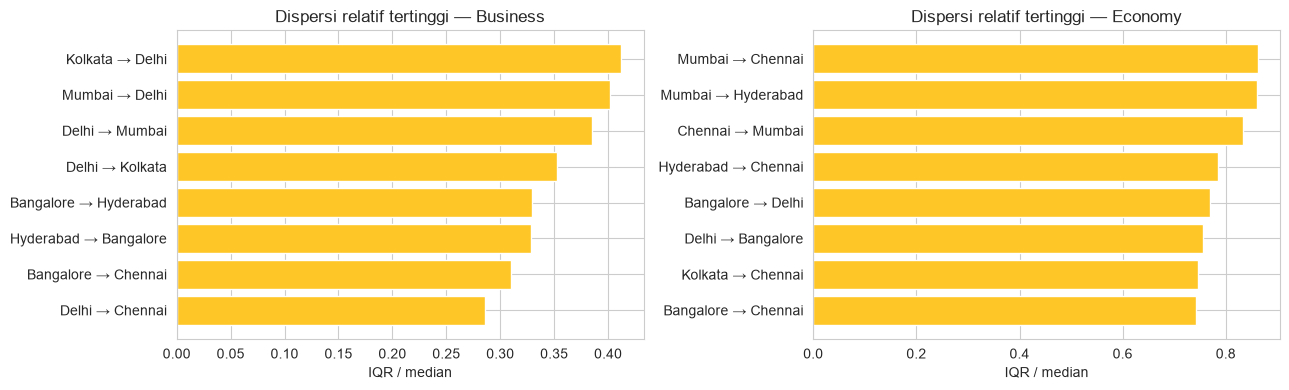

In [35]:
eda_route_summary=eda_data.groupby(['class','route'],observed=True).price.agg(
    n='size',median='median',p25=lambda x:x.quantile(.25),p75=lambda x:x.quantile(.75))
eda_route_summary['IQR_over_median']=(eda_route_summary.p75-eda_route_summary.p25)/eda_route_summary['median']
eda_route_eligible=eda_route_summary[eda_route_summary.n>=100].reset_index()
for eda_class,eda_part in eda_route_eligible.groupby('class'):
    print(f'\n{eda_class} — top 5 median harga (n>=100):')
    print(eda_part.nlargest(5,'median')[['route','n','median','IQR_over_median']].round(3).to_string(index=False))
    print(f'{eda_class} — top 5 dispersi relatif:')
    print(eda_part.nlargest(5,'IQR_over_median')[['route','n','median','IQR_over_median']].round(3).to_string(index=False))
    
    
fig,eda_ax=plt.subplots(1,2,figsize=(13,4))
for eda_a,(eda_class,eda_part) in zip(eda_ax,eda_route_eligible.groupby('class')):
    eda_top=eda_part.nlargest(8,'IQR_over_median').sort_values('IQR_over_median')
    eda_a.barh(eda_top.route,eda_top.IQR_over_median,color='#FFC627')
    eda_a.set_title(f'Dispersi relatif tertinggi — {eda_class}')
    eda_a.set_xlabel('IQR / median')
plt.tight_layout()
plt.show()

**Interpretasi:**
1. Pada kelas Business, beberapa rute dengan median harga tertinggi mencakup Kolkata–Bangalore, Bangalore–Kolkata, dan Chennai–Bangalore. Sementara itu, pada Economy, rute Bangalore–Kolkata memiliki median harga tertinggi di antara rute yang ditampilkan.
2. Berdasarkan rasio IQR terhadap median, variasi harga relatif lebih tinggi pada beberapa rute Economy, terutama Mumbai–Chennai dan Mumbai–Hyderabad, dengan rasio sekitar 0,86. Pada Business, rasio tertinggi yang ditampilkan berada di sekitar 0,41.
3. Temuan ini menunjukkan bahwa karakteristik rute berpotensi memengaruhi tingkat harga sekaligus variasinya. Oleh karena itu, kombinasi source_city dan destination_city dapat dipertimbangkan sebagai fitur rute dalam pemodelan, sementara performa prediksi dapat dianalisis lebih lanjut pada rute dengan variasi harga tinggi.

**Penemuan**

In [36]:

df2 = pd.read_csv('./raw_data/airlines_flights_data.csv')


bins = [0, 1, 3, 6, 12, float('inf')]
labels = [
    'Regional / Jarak Sangat Pendek (< 1 jam)',
    'Jarak Pendek (1 - 3 jam)',
    'Jarak Menengah (3 - 6 jam)',
    'Jarak Jauh (6 - 12 jam)',
    'Jarak Sangat Jauh / Ultra-long-haul (> 12 jam)'
]

# 3. Membuat kolom baru 'duration_category'
df2['duration_category'] = pd.cut(df2['duration'], bins=bins, labels=labels, right=False)

# 4. Menampilkan jumlah penerbangan di setiap kategori durasi
category_summary = df2['duration_category'].value_counts().reset_index()
category_summary.columns = ['Kategori Durasi', 'Jumlah Penerbangan']

print("=== Distribusi Kategori Durasi Penerbangan ===")
print(category_summary.to_string(index=False))

=== Distribusi Kategori Durasi Penerbangan ===
                               Kategori Durasi  Jumlah Penerbangan
Jarak Sangat Jauh / Ultra-long-haul (> 12 jam)              138449
                       Jarak Jauh (6 - 12 jam)              101996
                      Jarak Pendek (1 - 3 jam)               35384
                    Jarak Menengah (3 - 6 jam)               24194
      Regional / Jarak Sangat Pendek (< 1 jam)                 130


**Interpretasi:**

**"Pilih Mana: Langsung Cepat tapi Mahal, atau Transit Lama tapi Hemat?**

Berdasarkan data distribusi durasi, penerbangan berdurasi singkat di bawah 3 jam didominasi oleh penerbangan langsung (zero), sedangkan penerbangan jarak jauh sebagian besar menggunakan satu atau lebih transit. Dari segi harga, kelas Economy menunjukkan bahwa penerbangan langsung adalah yang termurah dan harganya meningkat seiring bertambahnya transit, sementara pada kelas Business, penerbangan langsung justru jauh lebih hemat dibandingkan penerbangan transit yang harganya melonjak drastis hingga mencapai ₹70.128.jadi tidak pasti dengan menggunakan transit lebih hemat ,harus di pertimbangkan dengan durasi penerbangan.


# Kesimpulan EDA
Berdasarkan hasil EDA, kelas penerbangan (class) menjadi faktor pembeda harga paling menonjol, dengan median harga Business sekitar 9,21 kali lebih tinggi dibandingkan Economy. Vistara juga cenderung memiliki harga lebih tinggi dibandingkan Air India, terutama pada kelas Business.

Selain itu, days_left memiliki hubungan negatif dengan harga, yaitu tiket cenderung lebih mahal ketika dipesan mendekati tanggal keberangkatan, khususnya pada kelas Economy. Sementara itu, pengaruh durasi dan jumlah transit bervariasi bergantung pada rute dan karakteristik penerbangan.

Secara keseluruhan, hasil EDA menunjukkan bahwa harga tiket berkaitan dengan kombinasi beberapa fitur, terutama kelas, maskapai, waktu pemesanan, dan rute. Temuan ini menjadi dasar dalam pemilihan fitur dan pengembangan model Airline Price Prediction.

# Preprocessing

In [37]:
X = df.drop(columns='price')
y = df['price']

print(f"Row and Columns X : {X.shape}")
print(f"Row and Columns y : {y.shape}")

Row and Columns X : (180090, 9)
Row and Columns y : (180090,)


In [38]:
X_train, y_train = train_raw[feature_cols].copy(), train_raw.price.copy()
X_val, y_val = val_raw[feature_cols].copy(), val_raw.price.copy()
X_test, y_test = test_raw[feature_cols].copy(), test_raw.price.copy()
assert 'price' not in X_train and 'flight' not in X_train
assert X_train.index.intersection(X_test.index).empty

Notes: Kode ini memisahkan dataset menjadi fitur prediktor (X) dan target harga tiket (y) pada data training, validation, dan testing.

**Tujuan:** Menyiapkan data untuk pemodelan sekaligus melakukan pemeriksaan awal untuk mencegah kebocoran target (target leakage) dan tumpang tindih indeks.

In [39]:
print('\nRaw Data proportion :')
print(df['class'].value_counts(normalize=True) * 100)
print('\nX_Train proportion :')
print(X_train['class'].value_counts(normalize=True) * 100)
print('\nX_test proportion :')
print(X_test['class'].value_counts(normalize=True) * 100)


Raw Data proportion :
class
Economy     68.773391
Business    31.226609
Name: proportion, dtype: float64

X_Train proportion :
class
Economy     68.773391
Business    31.226609
Name: proportion, dtype: float64

X_test proportion :
class
Economy     69.030043
Business    30.969957
Name: proportion, dtype: float64


Notes: Kode ini membandingkan persentase Economy dan Business pada dataset awal, training, dan testing.

**Interpretasi:** Proporsi kelas penerbangan relatif konsisten di seluruh dataset. Ini menunjukkan bahwa pembagian data mempertahankan komposisi Economy dan Business dengan baik.

# Encoding dan Scaling

In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor

num_cols = ['duration', 'days_left']
ohe_cols = ['class', 'airline', 'source_city', 'destination_city',
            'departure_time', 'arrival_time']


In [41]:
def preprocesing(scale=True):
  col_trans = ColumnTransformer([
      ('num', StandardScaler() if scale else 'passthrough', num_cols),
      ('stop', OrdinalEncoder(categories=[['zero', 'one', 'two_or_more']]),['stops']),
      ('ohe', OneHotEncoder(drop='if_binary',handle_unknown='ignore'), ohe_cols)
  ])
  return col_trans

# Modeling

In [42]:
models = [
    ('Linear Regression', Pipeline([
        ('prep',preprocesing(scale=True)),
        ('model',LinearRegression())
    ])),
    ('Ridge Regression', Pipeline([
        ('prep',preprocesing(scale=True)),
        ('model',Ridge())
    ])),
    ('Decision Tree Regressor', Pipeline([
        ('prep',preprocesing(scale=False)),
        ('model',DecisionTreeRegressor(random_state=42))
    ])),
    ('Random Forest', Pipeline([
        ('prep',preprocesing(scale=False)),
        ('model',RandomForestRegressor(n_estimators=100,min_samples_leaf=5,max_features=0.5,random_state=42,n_jobs=-1))
    ])),
    ('Gradient Boosting', Pipeline([
        ('prep',preprocesing(scale=False)),
        ('model',GradientBoostingRegressor(random_state=42))
    ])),
]

### Evaluation

In [43]:
result = []


for name, model in models :
  model.fit(X_train, y_train)
  y_pred = model.predict(X_val)
  result.append({
      'Model' : name,
      'MAE' : mean_absolute_error(y_val,y_pred),
      'R2' : r2_score(y_val,y_pred)
  }
  )

In [44]:
result_= pd.DataFrame(result).sort_values(by='R2',ascending=False)
print(result_.to_string(index=False))

                  Model         MAE       R2
          Random Forest 1302.864325 0.985119
Decision Tree Regressor 1172.165876 0.977344
      Gradient Boosting 2932.923570 0.952691
       Ridge Regression 4526.656828 0.909658
      Linear Regression 4526.624113 0.909658


/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_64918/1212048795.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  axe=sns.barplot(data=result_, x='Model', y='R2', palette='Wistia' , ax=ax[0])
/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_64918/1212048795.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  axe = sns.barplot(data=result_, x='Model', y='MAE', palette='Wistia', ax=ax[1])


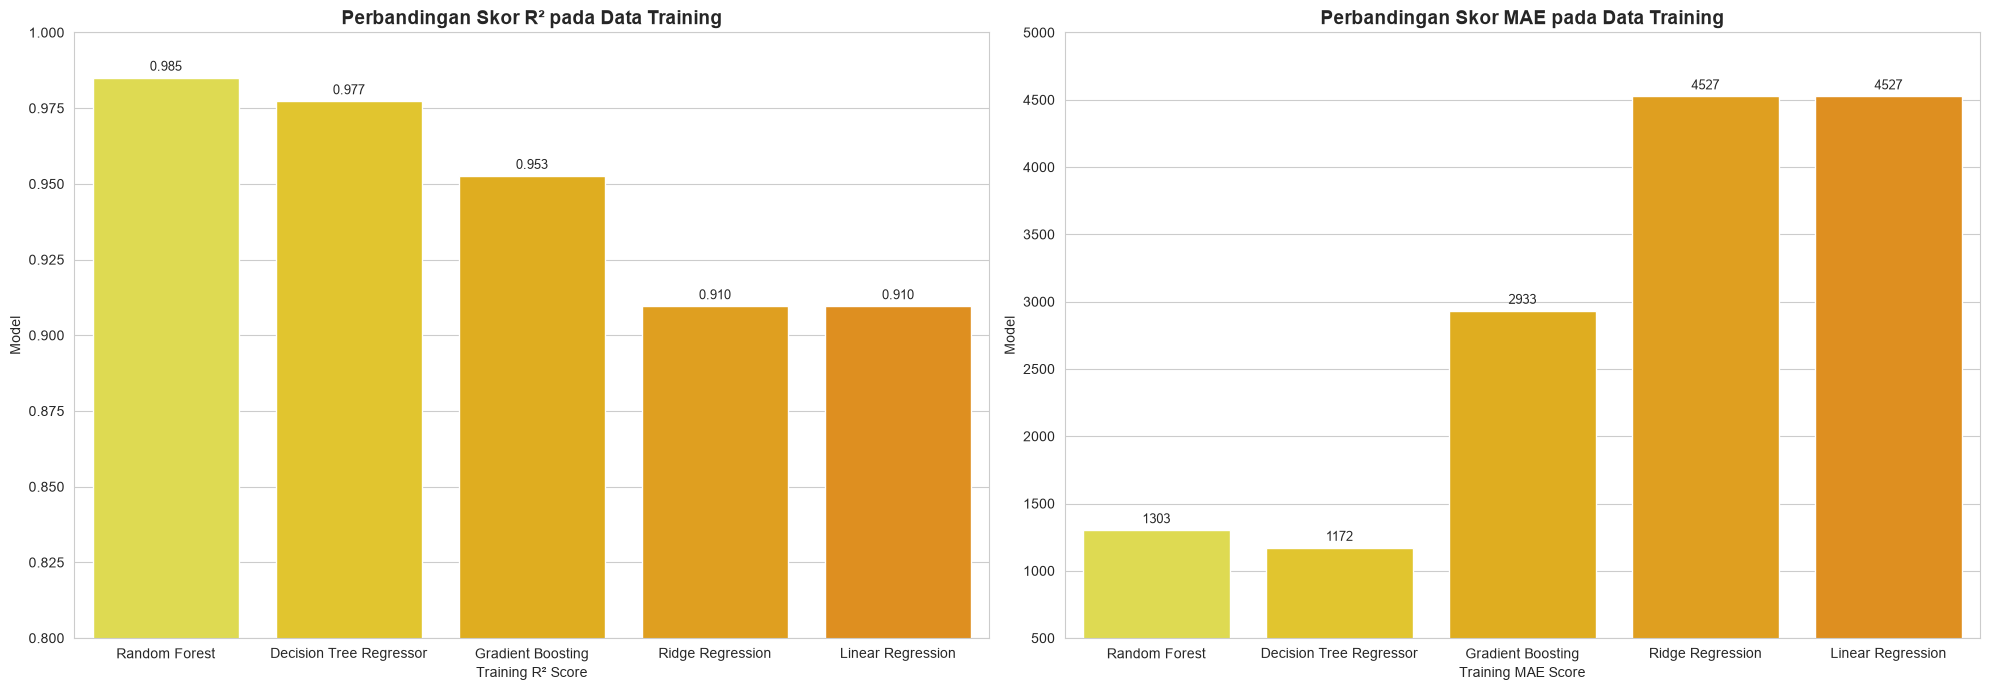

In [67]:
fig,ax = plt.subplots(1,2, figsize=(20,7))
axe=sns.barplot(data=result_, x='Model', y='R2', palette='Wistia' , ax=ax[0])
ax[0].set_title('Perbandingan Skor R² pada Data Training', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Training R² Score')
ax[0].set_ylabel('Model')
ax[0].set_ylim(0.8, 1.0)
for c in ax[0].containers:
    ax[0].bar_label(c, fmt='%.3f', padding=3, fontsize=9)

axe = sns.barplot(data=result_, x='Model', y='MAE', palette='Wistia', ax=ax[1])
ax[1].set_title('Perbandingan Skor MAE pada Data Training', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Training MAE Score')
ax[1].set_ylabel('Model')
ax[1].set_ylim(500, 5000)
for c in ax[1].containers:
    ax[1].bar_label(c, fmt='%.0f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

**Interpretasi**

Berdasarkan evaluasi antar model di atas, model terbaik adalah **Random Forest** karena secara keseluruhan model ini memiliki $R^2$ tertinggi sebesar (0.985) dengan error MAE yang maish sangat rendah

dari evaluasi tersebut juga dapat dilihat bahwa model berbasis pohon seperti (**Random Forest, Decision Tree Regressor, Gradient Boosing**) lebih baik dari model model linear seperti (**Linear Regression dan Ridge Regression**). Ini membuktikan bahwa hubungan antara fitur dengan target itu tidak bersifat linear

In [71]:
import time
def evaluation(name,model,X_tr,y_tr,X_val,y_val):
  tf= time.perf_counter()
  model.fit(X_tr,y_tr)
  fit =time.perf_counter() - tf

  pred_tr,pred_val = model.predict(X_tr),model.predict(X_val)

  r= {
      'Model' : name,
      'Train_MAE' : mean_absolute_error(y_tr,pred_tr),
      'Val_MAE' : mean_absolute_error(y_val,pred_val),
      'Train_R2' : r2_score(y_tr,pred_tr),
      'Val_R2' : r2_score(y_val,pred_val),
      'Fit_time' : fit
  }

  return r


result= [evaluation(name,model,X_train,y_train,X_val,y_val) for name,model in models]
result_= pd.DataFrame(result).sort_values(by='Val_R2',ascending=False)
print(result_.to_string(index=False))

                  Model   Train_MAE     Val_MAE  Train_R2   Val_R2  Fit_time
          Random Forest 1105.121860 1302.864325  0.989122 0.985119 19.074928
Decision Tree Regressor   73.794288 1172.165876  0.999101 0.977344 10.757298
      Gradient Boosting 2943.988857 2932.923570  0.952381 0.952691  5.220503
       Ridge Regression 4525.104421 4526.656828  0.909749 0.909658  0.140045
      Linear Regression 4525.071281 4526.624113  0.909749 0.909658  0.166553


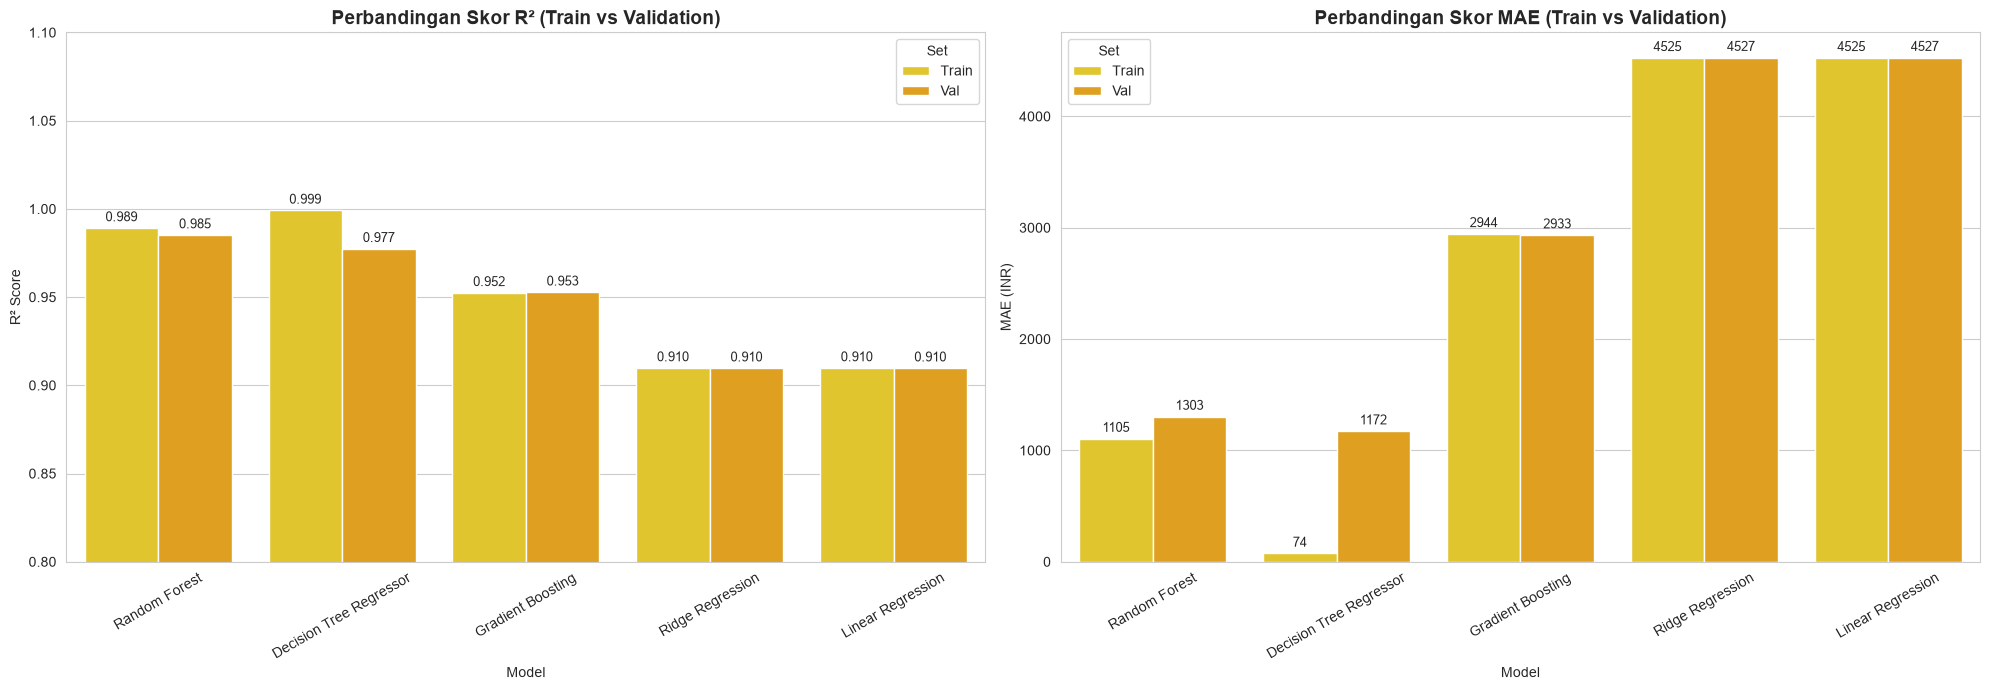

In [75]:
r2_long = result_.melt(id_vars='Model', value_vars=['Train_R2', 'Val_R2'],
                       var_name='Set', value_name='R2')
mae_long = result_.melt(id_vars='Model', value_vars=['Train_MAE', 'Val_MAE'],
                        var_name='Set', value_name='MAE')

r2_long['Set']  = r2_long['Set'].str.replace('_R2', '')
mae_long['Set'] = mae_long['Set'].str.replace('_MAE', '')

fig, ax = plt.subplots(1, 2, figsize=(20, 7))

sns.barplot(data=r2_long, x='Model', y='R2', hue='Set',
            palette='Wistia', ax=ax[0])
ax[0].set_title('Perbandingan Skor R² (Train vs Validation)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Model')
ax[0].set_ylabel('R² Score')
ax[0].set_ylim(0.8, 1.1)
ax[0].tick_params(axis='x', rotation=30)
for c in ax[0].containers:
    ax[0].bar_label(c, fmt='%.3f', padding=3, fontsize=9)

sns.barplot(data=mae_long, x='Model', y='MAE', hue='Set',
            palette='Wistia', ax=ax[1])
ax[1].set_title('Perbandingan Skor MAE (Train vs Validation)', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Model')
ax[1].set_ylabel('MAE (INR)')
ax[1].tick_params(axis='x', rotation=30)
for c in ax[1].containers:
    ax[1].bar_label(c, fmt='%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()


**Interpretasi**

Berdasarkan evaluasi menggunakan data train dan data validation, **Random Forest** terpilih sebagai model terbaik, dapat dilihat untuk pengecekan antar model dan juga pengecekan performa data train dan data validation di 2 evaluasi di atas model **Random Forest** memiliki performa yang sangat kuat, dengan error yang rendah dan kosisten antara data train dan data validationya meskipun waktu training dari **Random Forest** adalah waktu yang paling lama

In [76]:
class_mean = y_train.groupby(X_train['class']).mean()
pred_base = X_val['class'].map(class_mean)
result.append({
    'Model' : 'Baseline',
    'Val_MAE' : mean_absolute_error(y_val,pred_base),
    'Val_R2' : r2_score(y_val,pred_base)
})

result_= pd.DataFrame(result).sort_values(by='Val_R2',ascending=False)
print(result_.to_string(index=False))


                  Model   Train_MAE     Val_MAE  Train_R2   Val_R2  Fit_time
          Random Forest 1105.121860 1302.864325  0.989122 0.985119 19.074928
Decision Tree Regressor   73.794288 1172.165876  0.999101 0.977344 10.757298
      Gradient Boosting 2943.988857 2932.923570  0.952381 0.952691  5.220503
       Ridge Regression 4525.104421 4526.656828  0.909749 0.909658  0.140045
      Linear Regression 4525.071281 4526.624113  0.909749 0.909658  0.166553
               Baseline         NaN 4920.673711       NaN 0.878253       NaN


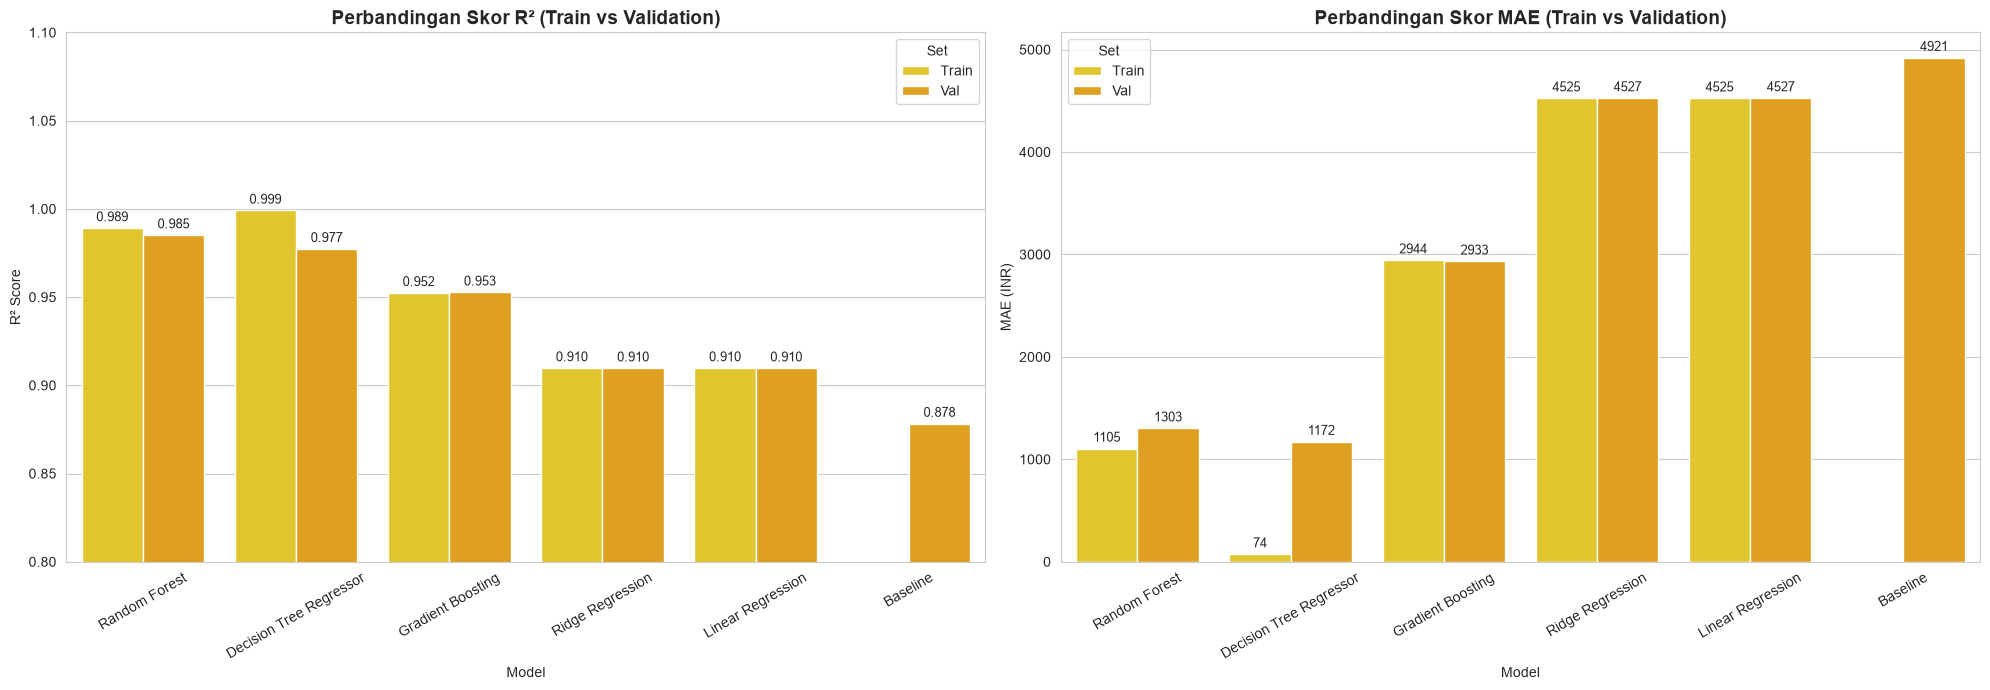

In [77]:
r2_long = result_.melt(id_vars='Model', value_vars=['Train_R2', 'Val_R2'],
                       var_name='Set', value_name='R2')
mae_long = result_.melt(id_vars='Model', value_vars=['Train_MAE', 'Val_MAE'],
                        var_name='Set', value_name='MAE')

r2_long['Set']  = r2_long['Set'].str.replace('_R2', '')
mae_long['Set'] = mae_long['Set'].str.replace('_MAE', '')

fig, ax = plt.subplots(1, 2, figsize=(20, 7))

sns.barplot(data=r2_long, x='Model', y='R2', hue='Set',
            palette='Wistia', ax=ax[0])
ax[0].set_title('Perbandingan Skor R² (Train vs Validation)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Model')
ax[0].set_ylabel('R² Score')
ax[0].set_ylim(0.8, 1.1)
ax[0].tick_params(axis='x', rotation=30)
for c in ax[0].containers:
    ax[0].bar_label(c, fmt='%.3f', padding=3, fontsize=9)

sns.barplot(data=mae_long, x='Model', y='MAE', hue='Set',
            palette='Wistia', ax=ax[1])
ax[1].set_title('Perbandingan Skor MAE (Train vs Validation)', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Model')
ax[1].set_ylabel('MAE (INR)')
ax[1].tick_params(axis='x', rotation=30)
for c in ax[1].containers:
    ax[1].bar_label(c, fmt='%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()


**Interpretasi**

Dengan menambahakn baseline ini bisa mengecek apakah model benar benar bekerja dengan baik dengan menemukan pola di data atau hanya menebak secara acak. Dapat dilihat dari evaluasi di atas semua model memiliki error yang jauh lebih rendah dari baseline dan score r2 nya juga jauh lebih besar daripada baseline model ini artinya model bener bener bisa menemukan pola dan tidak asal menebak harga

/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_67785/1101364490.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=result_, x='Val_R2', y='Model', palette='Wistia')


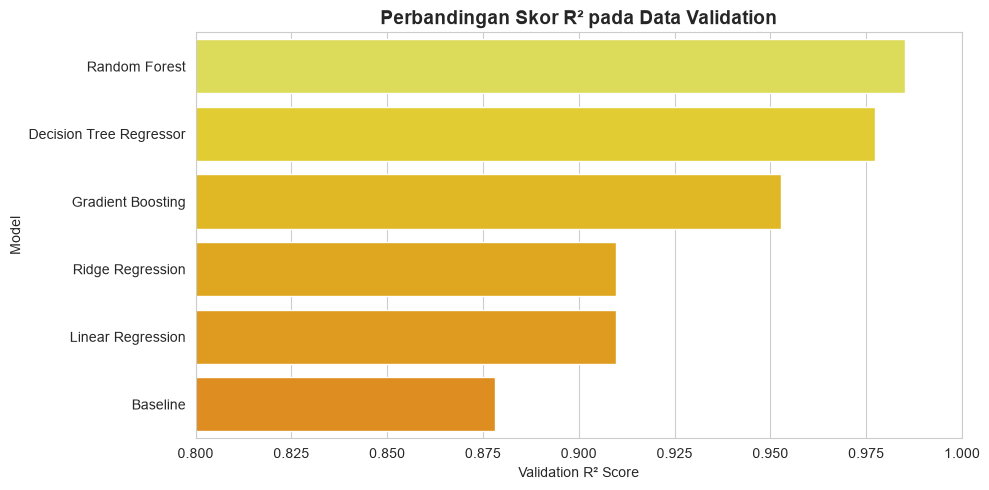

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=result_, x='Val_R2', y='Model', palette='Wistia')
plt.title('Perbandingan Skor R² pada Data Validation', fontsize=14, fontweight='bold')
plt.xlabel('Validation R² Score')
plt.ylabel('Model')
plt.xlim(0.8, 1.0)
plt.tight_layout()
plt.show()

### Cross Validation & Finetuning

In [ ]:
X_train.shape

(180090, 9)

In [ ]:
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)

feature_cols_for_group = [c for c in X_train.columns if c != 'flight']
train_groups = pd.util.hash_pandas_object(
    X_train[feature_cols_for_group], index=False
)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
param = {
    'model__n_estimators' :[100,200,300] ,
    'model__max_features': ['sqrt',0.5,1.0] ,
    'model__min_samples_leaf':[1,2,5],
    'model__max_depth': [10,20,None]

}

rf_pipline = Pipeline([
    ('prep',preprocesing(scale=False)),
    ('model',RandomForestRegressor(random_state=42,n_jobs=-1))
])

search = RandomizedSearchCV(
    estimator = rf_pipline,
    param_distributions = param,
    cv=gkf,
    verbose=2,
    scoring='r2',
    n_iter=8,
    random_state=42
)

search.fit(X_train,y_train, groups=train_groups)

print(f'Best Score : {search.best_score_}')
print(f'Best Params : {search.best_params_}')



Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=100; total time=  12.1s
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=100; total time=  11.5s
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=100; total time=  11.6s
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=100; total time=  11.4s
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=100; total time=  11.9s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__n_estimators=100; total time=   1.0s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__n_estimators=100; total time=   1.0s
[CV] END model__max_depth=10, model__max_features=s

**Interpretasi**

Best Score : 0.9840854512811795

Best Params : {'model__n_estimators': 200, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': None}

Berdasarkan hasil Cross Validation & Finetuning yang dilakukan hasilnya tidak jauh lebih baik dari default parameter **Random Forest** dapat dilihat hasil score after Cros Validation & Finetuning (0.984) sedangkan **Random Forest** dengan default parameter mendapatkan hasi sedikit lebih tinggi (0.985) 

---

**Kesimpulan**

Berdasarkan rangkaian eksperimen dan evaluasi model, Random Forest dengan parameter default terpilih sebagai model final karena menghasilkan performa tertinggi dengan skor validasi dan test $R^2$ sebesar 0.9851 serta MAE yang sangat rendah, mengungguli hasil hyperparameter tuning (0.9840)

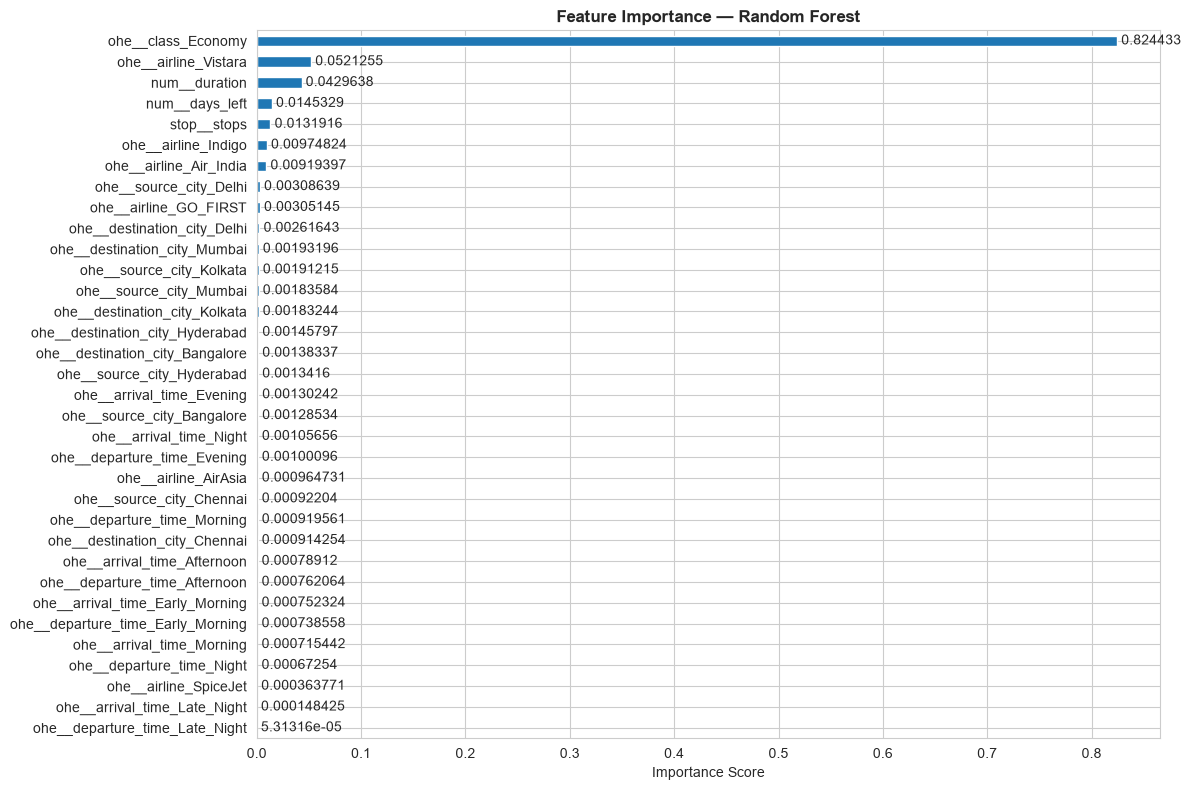

In [ ]:

rf_pipeline_model = dict(models)['Random Forest']
rf_model_inside = rf_pipeline_model.named_steps['model']
preprocessor = rf_pipeline_model.named_steps['prep']

encoded_feature_names = preprocessor.get_feature_names_out()

rf_featImp = pd.Series(
    rf_model_inside.feature_importances_, index=encoded_feature_names
).sort_values(ascending=True)

plt.figure(figsize=(12, 8))
ax = rf_featImp.plot(kind='barh')
plt.title(
    'Feature Importance — Random Forest', fontsize=12, fontweight='bold'
)
plt.xlabel('Importance Score')
plt.bar_label(ax.containers[0], padding=3)
plt.tight_layout()
plt.show()

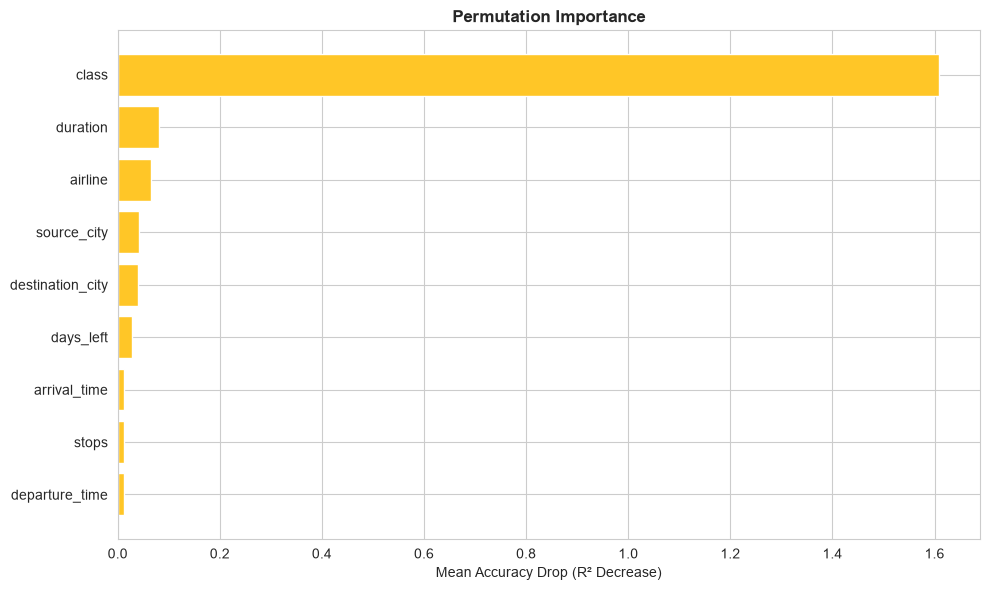

In [ ]:
from sklearn.inspection import permutation_importance

best_rf_model = dict(models)['Random Forest']

result_perm = permutation_importance(
    best_rf_model,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring='r2',
    n_jobs=-1,
)

perm_sorted_idx = result_perm.importances_mean.argsort()

plt.figure(figsize=(10, 6))
plt.barh(
    X_val.columns[perm_sorted_idx],
    result_perm.importances_mean[perm_sorted_idx],
    color='#FFC627',
)
plt.title(
    'Permutation Importance',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Mean Accuracy Drop (R² Decrease)')
plt.tight_layout()
plt.show()

In [ ]:
final_model = dict(models)['Random Forest']
y_pred = final_model.predict(X_test)
print(f'Test MAE : {mean_absolute_error(y_test,y_pred)}')
print(f'Test R2 : {r2_score(y_test,y_pred)}')

Test MAE : 1307.0106506275058
Test R2 : 0.985101850903218


In [ ]:
x_full = pd.concat([X_train,X_val])
y_full = pd.concat([y_train,y_val])

final_model.fit(x_full,y_full)

test_pred = final_model.predict(X_test)
test_scores = {
    'MAE': float(mean_absolute_error(y_test, test_pred)),
    'RMSE': float(mean_squared_error(y_test, test_pred) ** 0.5),
    'R2': float(r2_score(y_test, test_pred)),
}

print(test_scores)

{'MAE': 1239.306227355974, 'RMSE': 2685.0941500018507, 'R2': 0.9858705370314437}


In [ ]:
import joblib, json, sklearn, datetime
from sklearn.base import clone

joblib.dump(final_model, 'airline_price_model.joblib', compress=3)

metadata = {
    'trained_at': datetime.datetime.now().isoformat(timespec='seconds'),
    'sklearn_version': sklearn.__version__,
    'pandas_version': pd.__version__,
    'feature_cols': feature_cols,
    'categories': {c: sorted(x_full[c].unique().tolist())
                   for c in x_full.select_dtypes('object').columns},
    'duration_range': [float(x_full.duration.min()), float(x_full.duration.max())],
    'days_left_range': [int(x_full.days_left.min()), int(x_full.days_left.max())],
    'test_scores': test_scores,
    'currency': 'INR',
}
json.dump(metadata, open('model_metadata.json', 'w'), indent=2)

/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_67785/1505805979.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in x_full.select_dtypes('object').columns},
